# Reimplementation of Torre et al. (ACM TOSEM 2025) on TON-IoT

**Paper.** D. Torre, A. Chennamaneni, J. Jo, G. Vyas, B. Sabrsula. *Toward Enhancing Privacy Preservation of a
Federated Learning CNN Intrusion Detection System in IoT: Method and Empirical Study.* ACM Transactions on Software
Engineering and Methodology 34(2), Article 53, 2025. https://doi.org/10.1145/3695998

**What this notebook does.** It reimplements the paper's complete method: a 4-client federated 1D-CNN intrusion
detector with three privacy-preservation (PP) layers, which are Differential Privacy (DP), Diffie-Hellman (DH) key
exchange and the paper's "Homomorphic Encryption" (HE). It runs the paper's two experiments (FL without PP, FL with PP)
on the **TON-IoT** network dataset only, and compares the results with the paper's Tables 3, 10, 11 and 12.

**How to read it.** Every cell has been executed and its output is saved.
- Sections 1–2: the method and the assumptions.
- Section 3: the source code (it can be skipped).
- Sections 4–8: checks, experiments and results.
- Section 9: the discussion.

**Sources of information.** The paper has no public code. Every implementation choice is labelled as one of:
- **[PAPER]**: stated by the authors.
- **[PRIVACYFL]**: taken from the PrivacyFL simulator (Mugunthan et al., ref. [59]). The paper builds its DP and DH
  layers on PrivacyFL, but it is not the authors' own code.
- **[ASSUMPTION]**: not reported in the paper, so chosen here.

## 1. The method (as reimplemented)

**Federated learning protocol (Fig. 3, Sections 3.1–3.9) [PAPER]**
- 4 clients and 1 server; up to 10 FL iterations.
- The dataset is shuffled and cut into **40 equal pieces**, one per (client, iteration). Each piece is split
  **75 % train / 25 % test**.
- In each iteration, every client does the following:
  1. **Step 2:** trains the CNN on its piece, starting from the last federated model, and obtains L1. A lock and a
     barrier serialise CNN training across clients.
  2. **Step 3:** copies L1 to L2 and encrypts L2 with DP, then DH, then HE.
- The server then does the following:
  1. **Step 4:** decrypts the HE of each client.
  2. **Step 5:** averages the client models (FedAvg).
  3. **Step 6:** adds a fixed offset and re-applies HE for each client.
- Each client then does the following:
  1. **Step 7:** reverses the HE, removes the fixed offset, then removes its DP noise.
  2. **Step 8:** measures the local (L-A) and federated (F-A) accuracy on its 25 % test part.
  3. Leaves training when `max|federated − local| ≤ 0.0005` holds for both weights and biases.
- Simulated client latencies are 0.6, 3, 5 and 6 s, used to compute the client computation time (CCT) and the
  time to receive the federated data (TFD).

**CNN (Algorithm 1, Fig. 4) [PAPER]**
- Layers: Input → Conv1D(32, kernel 3, ReLU) → MaxPool1D(2) → Flatten → Dense(128, ReLU) → Dropout(0.5) →
  BatchNormalization → Dense(softmax).
- Training: categorical cross-entropy, Adam, batch 512, 10 epochs per iteration.

**DP layer (Algorithm 2, Sections 3.3 and 3.10.1)**
- Each element gets `μ/n + Gamma(1/n, λ) − Gamma(1/n, λ)`. Summed over the n clients, these shares are exactly
  Laplace(μ, λ), which is the paper's equation `L(μ,λ) = μ/n + Σ(γ_p − γ'_p)`.
- The Gamma shape 1/n comes from **[PRIVACYFL]**.
- λ is not reported for the experiments. The default λ = 0.1 is the paper's worked example (§3.10.1).

**DH layer (Algorithm 3) [PAPER + PRIVACYFL]**
- Pairwise ECDH secrets are turned into integer deltas.
- Each client adds the deltas of the clients listed before it and subtracts those of the clients after it, as one
  total offset `O_tot`. The offsets therefore cancel exactly in the server's average.
- The deltas are re-derived after every use.

**HE layer (Algorithms 4 and 5) [PAPER]**
- For each list of values, one operation is chosen at random (add, subtract, multiply or divide), together with an
  integer `B_I`. The operation is applied to the integer part of each element, as in Eqs. (1)–(4).
- Division is never chosen for a list whose operand is zero; for division, `B_I` is a factor of the operand.
- A sign rule keeps the integer and fractional parts consistent.
- The key material is stored in directories `D_X` / `D_Y`, which the server uses to decrypt **before** averaging.

**Metrics (Section 4.3) [PAPER]**
- Per-class one-vs-rest accuracy, precision, recall and F1.
- The overall row (Table 10) is the mean over the classes. This was checked against the paper: averaging Table 3
  reproduces Table 10 exactly.

## 2. Assumptions, deviations and known issues in the paper

**Choices that affect results** (each one is a switch, and an ablation was run for it in Section 7):

| ID | Item | Choice here | Why |
|---|---|---|---|
| A1 | BatchNorm / Dropout | in the model (Fig. 4) | Algorithm 1 creates them but never connects them; Fig. 4 and the text include them |
| A2 | DP noise removal (Step 7) | subtract own noise ÷ active clients | [PRIVACYFL]; the paper only says "subtraction of the noise" |
| A3 | What "weights and biases" (L2) are | the trainable parameters | §1.1: "the learnable parameters"; adding noise to BatchNorm's running variance makes it negative (NaN models) |
| A4 | DP scale λ | 0.1 | the paper's worked example; neither Δ nor ε is reported |
| A5 | Initial weights | the same for all clients | FedAvg convention; not stated in the paper |
| A15 | Feature scaling for TON-IoT | MinMaxScaler | §4.2 lists none for TON-IoT, but raw values reach 3.9 × 10⁹ and the CNN then predicts almost only Normal |

**Other assumptions**
- HE: `B_I` is drawn from 1..100. The server's fixed offset is 7919. A sign-flip record is added to the directory,
  without which decryption is not exact.
- The 40 pieces are split at random, without stratification.
- The binary `label` column is dropped, because it is a copy of the target.
- The final per-class evaluation is each client's final federated model on its own 10 test parts, pooled over the
  4 clients. The paper does not say how its tables were computed.
- Libraries: TensorFlow 2.20 / Keras 3, where the paper used 2.11. The PP arithmetic runs in float64.

**Deliberate deviation**
- Preprocessing is fitted on the training rows only, to avoid test leakage. The paper fits it before splitting.

**Issues found in the paper**
1. **The "HE" layer is not homomorphic encryption.** The server reverses it before averaging, so no computation is
   ever done on ciphertexts, and the server can read every client's (noised, offset) model.
2. **No ε is reported for the DP layer.** The weights are never clipped, so the sensitivity is unbounded, and the
   noise cannot be calibrated to any finite ε as specified.
3. **Internal inconsistencies.**
   - The average recall in the abstract (92.43) differs from the one Table 10 gives (92.28).
   - Some per-class F1 values cannot follow from the reported precision and recall. EdgeIIoT MITM is reported with
     P 99.96, R 100 and F1 85.29.
4. **The dataset has 11,071 exact duplicate rows (2.4 %).** They are kept here, as in the paper, so a row can appear
   in both a training and a test part.

## 3. Source code

The package is written to disk below, so the notebook runs on its own. It is the same code as `torre2025_fl_cnn_pp/`
in the repository, which also has 24 unit tests.
- `privacy.py`: DP, DH and HE.
- `fl.py`: the client and server agents.
- `data.py`: loading and preprocessing.
- `model.py`: the CNN.

**This section can be skipped.**

In [1]:
import os
os.makedirs('torre2025_fl_cnn_pp', exist_ok=True)

In [2]:
%%writefile torre2025_fl_cnn_pp/__init__.py
# package marker


Writing torre2025_fl_cnn_pp/__init__.py


In [3]:
%%writefile torre2025_fl_cnn_pp/config.py
"""Central configuration for the reimplementation of

    Torre, Chennamaneni, Jo, Vyas, Sabrsula. "Toward Enhancing Privacy Preservation of a
    Federated Learning CNN Intrusion Detection System in IoT: Method and Empirical Study".
    ACM TOSEM 34(2), Article 53, 2025. https://doi.org/10.1145/3695998

Every field is tagged with its provenance:
    [PAPER §x]     value stated by the authors (section / algorithm / table)
    [PRIVACYFL]    taken from PrivacyFL (Mugunthan et al., ref [59]), the simulator the paper's DP and
                   DK layers are built on. This is NOT the authors' own code, which is not public.
    [ASSUMPTION]   not reported in the paper; chosen by this reimplementation (see README, "Assumptions")
"""
from dataclasses import asdict, dataclass, replace


@dataclass(frozen=True)
class Config:
    # ---------------- FL topology (Section 3, 3.1, 3.9) ----------------
    n_clients: int = 4                      # [PAPER §3] four clients, one server
    max_iterations: int = 10                # [PAPER §3, §3.9] up to 10 FL iterations per client
    tolerance: float = 0.0005               # [PAPER §3.8] max |federated - local| for convergence
    # Communication latencies C1..C4 in seconds (Section 4.4). Applied in both directions.
    latencies_s: tuple = (0.6, 3.0, 5.0, 6.0)   # [PAPER §4.4]

    # ---------------- Data split (Section 3.1) ----------------
    # Dataset split at random into n_clients * max_iterations equal pieces (40), one per client-iteration,
    # each piece split 75 % train / 25 % test.
    test_fraction: float = 0.25             # [PAPER §3.1]
    stratify_piece_split: bool = False      # [ASSUMPTION] paper says "random sampling", no stratification
    sample_frac: float = 1.0                # 1.0 = full dataset as in the paper. <1 only for development runs
    max_rows: int = 0                       # 0 = no cap. >0 only for development runs (logged in results)
    synthetic_rows: int = 200000            # size of the synthetic smoke/verification table (not a paper dataset)
    minmax: object = None                   # None = per-dataset default (data.SPECS); True/False = override
    drop_row_id_columns: bool = True        # [ASSUMPTION] drop pure row-index / record-ID columns (leakage)

    # ---------------- CNN (Algorithm 1, Fig. 4) ----------------
    # "fig4": Dense -> Dropout(0.5) -> BatchNormalization -> softmax (Fig. 4 and the text, layers L1..L8).
    # "algorithm1_literal": Algorithm 1 as printed, where Dropout and BatchNormalization are instantiated
    #  but the output layer is called on dense_layer_1, so they are not part of the graph.
    architecture: str = "fig4"              # [ASSUMPTION] choice between two contradictory paper sources
    conv_filters: int = 32                  # [PAPER Alg.1 l.2]
    kernel_size: int = 3                    # [PAPER Alg.1 l.2]
    pool_size: int = 2                      # [PAPER Alg.1 l.3]
    dense_units: int = 128                  # [PAPER Alg.1 l.5]
    dropout: float = 0.5                    # [PAPER Alg.1 l.6]
    batch_size: int = 512                   # [PAPER Alg.1 l.11]
    epochs: int = 10                        # [PAPER Alg.1 l.11]
    # Iteration 1: True = every client starts from the same initial weights (FedAvg convention, refs [44, 51]);
    # False = each client initialises its own CNN independently. The paper does not say which.
    common_initialization: bool = True      # [ASSUMPTION]
    learning_rate: float = 0.001            # [ASSUMPTION] Keras Adam default ("optimizer=adam")
    fit_verbose: int = 0                    # paper uses verbose=1; 0 keeps logs readable (no effect on results)

    # ---------------- Differential privacy (Algorithm 2, §3.3, §3.10.1) ----------------
    dp_mu: float = 0.0                      # [PAPER §3.10.1] worked example: mean 0
    # lambda = Delta / x (Section 3.3). Neither Delta nor x (epsilon) is reported for the experiments.
    # dp_scale_mode = "fixed": lambda = dp_fixed_scale (0.1 = the paper's worked example, §3.10.1)
    # dp_scale_mode = "sensitivity": lambda = Delta / dp_epsilon with Delta = max_i |x_i - y_i| computed
    #                 between the client's new local weights and the weights it started the iteration from.
    dp_scale_mode: str = "fixed"            # [ASSUMPTION]
    dp_fixed_scale: float = 0.1             # [PAPER §3.10.1] example scale 0.1
    dp_epsilon: float = 1.0                 # [PRIVACYFL] config.epsilon = 1.0 (used only in "sensitivity" mode)
    # How the client removes DP noise from the federated L2 (Step 7):
    #   "own_share": subtract own_noise / n_active   [PRIVACYFL client_agent.receive_weights]
    #   "own_full" : subtract own_noise              (literal reading of §3.7 "subtraction of the noise")
    dp_noise_removal: str = "own_share"     # [ASSUMPTION, PrivacyFL-backed]
    # Which Keras model arrays form L2 = "weights and biases" (exchanged with the server, encrypted, averaged
    # and compared for convergence). Every exchanged array goes through all three PP layers.
    #   "trainable": the learnable parameters (Section 1.1: "the weights and biases are the learnable
    #                parameters"); BatchNormalization moving statistics are not exchanged and stay local.
    #   "all"      : everything in model.get_weights(), including BN moving mean/variance.
    #   "conv"     : only the Conv1D kernel (3, 1, 32) and bias (32) -- Fig. 1 shows exactly these shapes and
    #                Section 3.1 describes L2 as one 3-D weight array plus one 1-D bias array.
    federated_arrays: str = "trainable"     # [ASSUMPTION]

    # ---------------- Diffie-Hellman offsets (Algorithm 3, §3.10.2) ----------------
    dh_curve: str = "SECP384R1"             # [PRIVACYFL] ECDH + HKDF-SHA256
    dh_delta_bits_slice: int = 20           # [PRIVACYFL] delta = int(bin(seed)[:20], 2)

    # ---------------- Homomorphic layer (Algorithms 4, 5, §3.3, §3.6) ----------------
    he_b_max: int = 100                     # [ASSUMPTION] B_I drawn uniformly from 1..he_b_max
    server_fixed_offset: int = 7919         # [ASSUMPTION] "fixed offset value" of Step 6 is not reported

    # ---------------- Reproducibility / IO ----------------
    seed: int = 42                          # [ASSUMPTION]
    deterministic_ops: bool = False         # True -> tf.config.experimental.enable_op_determinism()
    results_dir: str = "results_torre2025"
    save_checkpoints: bool = True

    def to_dict(self):
        return asdict(self)

    def with_overrides(self, **kw):
        return replace(self, **{k: v for k, v in kw.items() if v is not None})


# Smoke-test overrides: same code path, smaller compute. Used ONLY by tests and --smoke; never for results.
SMOKE_OVERRIDES = dict(epochs=2, batch_size=64, max_iterations=3, synthetic_rows=20000)


Writing torre2025_fl_cnn_pp/config.py


In [4]:
%%writefile torre2025_fl_cnn_pp/privacy.py
"""The three privacy-preservation (PP) layers of Torre et al. 2025, Section 3.3-3.7 and 3.10.

    DP  - Algorithm 2 and Section 3.10.1: Laplace noise built from Gamma differences (PrivacyFL, ref [59]).
    DK  - Algorithm 3 and Section 3.10.2: pairwise Diffie-Hellman offsets O_tot added to L2.
    HE  - Algorithm 4 (encryption) and Algorithm 5 (decryption): per-list random add/sub/mul/div applied
          to the integer part of every element, with the key material kept in directories D_X / D_Y.

A model ("L2") is a list of numpy arrays (Keras get_weights order). Arrays with ndim >= 2 are "weights"
(directory D_X), 1-D arrays are "biases" (directory D_Y), following Section 3.1. All PP arithmetic is done
in float64 so that adding large integer offsets does not destroy the fractional weight information.
"""
import random
import sys

import numpy as np
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives.asymmetric import ec
from cryptography.hazmat.primitives.kdf.hkdf import HKDF


def is_weight_array(a):
    """Weights (D_X) are >= 2-D arrays, biases (D_Y) are 1-D (Section 3.1)."""
    return np.ndim(a) >= 2


# =====================================================================================================
# DP: Algorithm 2 + equation L(mu, lambda) = mu/n + sum_{p=1..n} (gamma_p - gamma'_p)
# =====================================================================================================
def dp_scale_from_sensitivity(delta, epsilon):
    """lambda = Delta / x (Section 3.3); x is read as the privacy budget epsilon."""
    return float(delta) / float(epsilon)


def max_abs_difference(xs, ys):
    """Delta = max_i |x_i - y_i| (Section 3.3), over every element of two models."""
    return max(float(np.max(np.abs(np.asarray(x, np.float64) - np.asarray(y, np.float64))))
               for x, y in zip(xs, ys))


def laplace_gamma_noise(shapes, n_clients, mu, scale, rng):
    """One client's share of the distributed Laplace mechanism.

    Each element gets mu/n + (G1 - G2) with G1, G2 ~ Gamma(shape=1/n, scale=lambda) (Algorithm 2, lines 5-7).
    Summed over the n clients, the shares are exactly Laplace(mu, lambda) (divisibility of the Laplace law),
    which is the equation in Sections 3.3 / 3.10.1.
    """
    k = 1.0 / n_clients
    return [mu / n_clients + rng.gamma(k, scale, size=s) - rng.gamma(k, scale, size=s) for s in shapes]


def add_dp_noise(L2, n_clients, mu, scale, rng):
    """Algorithm 2: A = zeros(L.shape); fill A with Gamma-difference noise; L2 = L2 + A."""
    A = laplace_gamma_noise([np.shape(a) for a in L2], n_clients, mu, scale, rng)
    return [np.asarray(a, np.float64) + n for a, n in zip(L2, A)], A


# =====================================================================================================
# DK: Diffie-Hellman key agreement and Algorithm 3 offsets
# =====================================================================================================
_CURVES = {"SECP384R1": ec.SECP384R1, "SECP256R1": ec.SECP256R1}


class DiffieHellmanParty:
    """One client's DH state (PrivacyFL utils/diffie_hellman.py + ClientAgent.update_deltas).

    Phase 1 (initialisation): one private/public key pair per peer.
    Phase 2: public keys are exchanged.
    Phase 3 (key agreement): ECDH shared secret -> HKDF-SHA256 -> 256-bit integer common key.
    Deltas (the integer offsets for a peer) are derived from the common key and re-derived after every use
    from a portion of the previous seed (Section 3.3: "using a portion of the original delta as a seed").
    """

    def __init__(self, name, peer_names, curve="SECP384R1", bits_slice=20):
        self.name = name
        self.order = list(peer_names)          # directory order, identical for every client
        self.bits_slice = bits_slice
        self._priv = {p: ec.generate_private_key(_CURVES[curve]()) for p in self.order if p != name}
        self.public_keys = {p: k.public_key() for p, k in self._priv.items()}
        self.seeds = {p: 0 for p in self.order}
        self.deltas = {p: 0 for p in self.order}   # delta with yourself is 0 (Algorithm 3, line 10)
        self._agreed = False

    def agree(self, peer_public_keys):
        """peer_public_keys[p] = the public key that peer p generated for *this* client."""
        for p in self.order:
            if p == self.name:
                continue
            shared = self._priv[p].exchange(ec.ECDH(), peer_public_keys[p])
            key = HKDF(algorithm=hashes.SHA256(), length=32, salt=None, info=b"handshake data").derive(shared)
            self.seeds[p] = int.from_bytes(key, "big")
        self._agreed = True
        self.update_deltas()

    def update_deltas(self):
        """PrivacyFL update_deltas: delta = leading bits of the seed, next seed from the remaining bits."""
        for p in self.order:
            if p == self.name:
                continue
            seed_b = bin(self.seeds[p])
            self.deltas[p] = int(seed_b[: self.bits_slice], 2)
            rest = seed_b[self.bits_slice:]
            seed = int(rest, 2) if rest else 0
            self.seeds[p] = random.Random(seed).randint(-sys.maxsize, sys.maxsize)

    def offset_total(self, active):
        """Algorithm 3: deltas of clients before CC are added, deltas of clients after CC are subtracted.

        The sign convention makes sum_i O_tot(i) = 0 over the active clients, so the offsets cancel in the
        server's average while hiding every individual L2.
        """
        assert self._agreed, "key agreement must run before offsets are used"
        o_tot, add = 0, True
        for c in self.order:
            if c not in active:
                continue
            O = self.deltas[c]
            if c == self.name:
                add = False          # line 9: for all C after CC, ADD = false
                o_tot -= O           # line 10 (O is 0 for the client itself)
            elif add:
                o_tot += O           # line 12
            else:
                o_tot -= O           # ADD = false branch
        return o_tot


def diffie_hellman_setup(names, curve="SECP384R1", bits_slice=20):
    """Create every client's DH state and run the three-phase key exchange among all clients."""
    parties = {n: DiffieHellmanParty(n, names, curve, bits_slice) for n in names}
    for n, party in parties.items():
        party.agree({p: parties[p].public_keys[n] for p in names if p != n})
    return parties


def add_offset(L2, o_tot):
    """Algorithm 3, line 15: L2 += O_tot (the summed offset, added once to avoid precision loss)."""
    return [np.asarray(a, np.float64) + float(o_tot) for a in L2]


# =====================================================================================================
# HE: Algorithm 4 (encryption) and Algorithm 5 (decryption)
# =====================================================================================================
OPS = ("add", "subtract", "multiply", "divide")
_OP_CODE = {op: i for i, op in enumerate(OPS)}


def _lists(a):
    """The lists L of one array: rows along axis 0 for weights, the whole vector for biases."""
    a = np.asarray(a, np.float64)
    return a.reshape(a.shape[0], -1) if a.ndim >= 2 else a.reshape(1, -1)


def _split(v):
    """E -> (E_int, E_flt): integer part and signed fractional part (same sign as E)."""
    e_int = np.trunc(v)
    return e_int.astype(np.int64), v - e_int


def _random_factor(operand, b_max, rng):
    """Per element, a pseudo-random B_I in 1..b_max that is a factor of the (non-zero) operand."""
    cand = np.arange(1, b_max + 1, dtype=np.int64)
    ok = (np.abs(operand)[:, None] % cand[None, :]) == 0          # 1 always divides
    pick = np.argmax(rng.random(ok.shape) * ok, axis=1)
    return cand[pick]


def _encrypt_list(L, o_p, b_max, rng):
    e_int, e_flt = _split(L)
    operand = e_int - o_p                       # E_int without the previous layer's offset O_tot
    # Zero-division guard: if any element is 0 without O_tot, division is not allowed for this list.
    allowed = OPS[:3] if np.any(operand == 0) else OPS
    op = allowed[rng.integers(len(allowed))]
    if op == "divide":
        B = _random_factor(operand, b_max, rng)                    # B_I is a factor of E_int (Alg.4 l.21)
    else:
        B = np.int64(rng.integers(1, b_max + 1))                  # one list-wise B_I (Alg.4 l.10)
    if op == "add":
        new_int = e_int + B                                         # Eq. (1)
    elif op == "subtract":
        new_int = e_int - B                                         # Eq. (2)
    elif op == "multiply":
        new_int = operand * B + o_p                                 # Eq. (3)
    else:
        new_int = operand // B + o_p                                # Eq. (4), exact because B | operand
    # If E_int and E_flt do not have the same sign, E_flt = -E_flt (Alg.4 l.13-14, l.23-24).
    flip = (np.sign(new_int) * np.sign(e_flt)) < 0
    e_flt = np.where(flip, -e_flt, e_flt)
    enc = new_int.astype(np.float64) + e_flt                        # E = E_int + E_flt (Alg.4 l.26)
    entry = {"op": _OP_CODE[op], "B": B, "flip": flip, "o_p": int(o_p), "enc": enc.copy()}
    return enc, entry


def he_encrypt(L2, o_p, b_max, rng):
    """Algorithm 4. Returns the encrypted L2 and the directories {"D_X": ..., "D_Y": ...}.

    o_p is the integer offset of the previous encryption layer (O_tot on clients, the fixed offset on the
    server). Each directory maps array index -> list of per-list entries (operation code, B_I, sign-flip
    mask, O_p and the encrypted values used for the integrity check of Algorithm 5).
    """
    directory = {"D_X": {}, "D_Y": {}}
    out = []
    for idx, a in enumerate(L2):
        rows = _lists(a)
        enc_rows, entries = np.empty_like(rows), []
        for r in range(rows.shape[0]):
            enc_rows[r], entry = _encrypt_list(rows[r], o_p, b_max, rng)
            entries.append(entry)
        directory["D_X" if is_weight_array(a) else "D_Y"][idx] = entries
        out.append(enc_rows.reshape(np.shape(a)))
    return out, directory


def _inverse(entry, x):
    x_int, x_flt = _split(x)
    x_flt = np.where(entry["flip"], -x_flt, x_flt)                  # undo the sign inversion
    B, o_p, op = entry["B"], entry["o_p"], OPS[entry["op"]]
    if op == "add":
        e_int = x_int - B
    elif op == "subtract":
        e_int = x_int + B
    elif op == "multiply":
        e_int = (x_int - o_p) // B + o_p                             # exact: (x_int - o_p) = operand * B
    else:
        e_int = (x_int - o_p) * B + o_p
    return e_int.astype(np.float64) + x_flt


def he_decrypt(L2_enc, directory):
    """Algorithm 5: INVERSE_{E_opt} element-wise, then remove the used entries from D_X / D_Y."""
    out = []
    for idx, a in enumerate(L2_enc):
        key = "D_X" if is_weight_array(a) else "D_Y"
        entries = directory[key].pop(idx)                            # line 9: remove E from D_X / D_Y
        rows = _lists(a)
        if len(entries) != rows.shape[0]:
            raise ValueError(f"HE directory does not match array {idx}")
        dec = np.empty_like(rows)
        for r, entry in enumerate(entries):
            # Integrity check: the called list must hold the same values as recorded in the directory.
            if not np.array_equal(rows[r], entry["enc"]):
                raise ValueError(f"HE integrity check failed for array {idx}, list {r}")
            dec[r] = _inverse(entry, rows[r])
        out.append(dec.reshape(np.shape(a)))
    return out


Writing torre2025_fl_cnn_pp/privacy.py


In [5]:
%%writefile torre2025_fl_cnn_pp/model.py
"""Algorithm 1 / Fig. 4: the 1D CNN (layers L1..L8), its initialisation, compilation and training."""
import numpy as np


def build_cnn(input_len, n_classes, cfg):
    import keras
    from keras import layers

    input_layer = keras.Input(shape=(input_len, 1))                                            # L1
    conv = layers.Conv1D(filters=cfg.conv_filters, kernel_size=cfg.kernel_size,
                         activation="relu")(input_layer)                                       # L2
    pool = layers.MaxPooling1D(pool_size=cfg.pool_size)(conv)                                  # L3
    flat = layers.Flatten()(pool)                                                              # L4
    dense = layers.Dense(cfg.dense_units, activation="relu")(flat)                             # L5
    if cfg.architecture == "fig4":
        # Fig. 4 and Section 3.2 text: Dense -> Dropout -> BatchNormalization -> Output.
        hidden = layers.Dropout(cfg.dropout)(dense)                                            # L6
        hidden = layers.BatchNormalization()(hidden)                                           # L7
    elif cfg.architecture == "algorithm1_literal":
        # Algorithm 1 as printed: L6 and L7 are created but never called, and line 8 feeds
        # dense_layer_1 straight into the output layer, so they do not take part in the model.
        layers.Dropout(cfg.dropout)                                                            # L6
        layers.BatchNormalization()                                                            # L7
        hidden = dense
    else:
        raise ValueError(f"unknown architecture {cfg.architecture!r}")
    output_layer = layers.Dense(n_classes, activation="softmax")(hidden)                       # L8
    model = keras.Model(inputs=input_layer, outputs=output_layer)
    model.compile(loss="categorical_crossentropy",
                  optimizer=keras.optimizers.Adam(learning_rate=cfg.learning_rate),
                  metrics=["accuracy"])
    return model


def as_cnn_input(X):
    return np.asarray(X, np.float32)[..., None]


def one_hot(y, n_classes):
    return np.eye(n_classes, dtype=np.float32)[np.asarray(y, np.int64)]


def train_cnn(model, X, y, n_classes, cfg):
    """Algorithm 1 line 11: model.fit(x_train, y_train, batch_size=512, epochs=10).

    `use_multiprocessing=True` from the paper only affected Keras 2 generator inputs; Keras 3 removed the
    argument for array inputs, so it is not passed (no effect on training with in-memory arrays).
    """
    model.fit(as_cnn_input(X), one_hot(y, n_classes), batch_size=cfg.batch_size, epochs=cfg.epochs,
              verbose=cfg.fit_verbose, shuffle=True)
    return model


def predict_classes(model, X, batch_size=4096):
    return np.argmax(model.predict(as_cnn_input(X), batch_size=batch_size, verbose=0), axis=1)


def accuracy_with_weights(eval_model, weights, X, y):
    """Step 8: the CNN Evaluation Model is pre-initialised with the given weights and evaluated."""
    eval_model.set_weights([np.asarray(w, np.float32) for w in weights])
    probs = eval_model.predict(as_cnn_input(X), batch_size=4096, verbose=0)
    if not np.all(np.isfinite(probs)):
        return float("nan")                     # e.g. a negative BatchNorm variance after noise
    return float(np.mean(np.argmax(probs, axis=1) == np.asarray(y)))


Writing torre2025_fl_cnn_pp/model.py


In [6]:
%%writefile torre2025_fl_cnn_pp/metrics.py
"""Section 4.3 metrics.

Per class (one-vs-rest): accuracy (TP+TN)/(TP+TN+FP+FN), precision TP/(TP+FP), recall TP/(TP+FN),
F1 = 2PR/(P+R) (Tables 3-9). The per-dataset row of Table 10 is the unweighted mean of the per-class rows:
this was checked against the paper (mean of Table 3 columns = Table 10 TON-IoT row: 99.63/96.48/93.18/94.45).
"""
import numpy as np


def per_class_metrics(y_true, y_pred, class_names):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    rows = []
    for k, name in enumerate(class_names):
        t, p = y_true == k, y_pred == k
        tp = int(np.sum(t & p)); fp = int(np.sum(~t & p)); fn = int(np.sum(t & ~p)); tn = n - tp - fp - fn
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        rows.append({"class": name, "support": int(np.sum(t)), "A": 100 * (tp + tn) / n,
                     "P": 100 * prec, "R": 100 * rec, "F1": 100 * f1})
    return rows


def overall_from_per_class(rows):
    """Table 10 row: mean over classes of A, P, R, F1 (classes with no test support are excluded)."""
    rows = [r for r in rows if r["support"] > 0]
    return {m: float(np.mean([r[m] for r in rows])) for m in ("A", "P", "R", "F1")}


Writing torre2025_fl_cnn_pp/metrics.py


In [7]:
%%writefile torre2025_fl_cnn_pp/data.py
"""Step 1 (Section 3.1) and Section 4.2: loading, pre-processing and splitting of the seven IoT datasets.

Order of operations (leakage-safe version of the paper's pipeline):
  1. load raw rows, map the raw attack labels to the classes of Tables 3-9 and drop the classes the paper
     excludes (row-wise, stateless);
  2. shuffle with the seed and cut the data into n_clients * max_iterations equal pieces (40); split each
     piece 75 % / 25 % at random (Section 3.1);
  3. FIT every data-dependent transform (column typing, empty-column removal, LabelEncoder, MinMaxScaler)
     on the union of the 75 % training parts only, then apply it to every part.
The paper pre-processes before splitting (Fig. 3); fitting on training rows only is the one deliberate
change, requested to avoid test-set leakage. The transforms themselves are the ones in Section 4.2.
"""
import glob
import hashlib
import json
import os
import re
from dataclasses import dataclass, field, replace

import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------------------------------
# Label mappings. Class order = row order of the paper's per-dataset result table.
# -----------------------------------------------------------------------------------------------------
TON_IOT_MAP = {"normal": "Normal", "ddos": "DDoS", "scanning": "Reconnaissance", "backdoor": "Backdoor",
               "injection": "Injection", "password": "Password", "ransomware": "Ransomware", "xss": "XSS",
               "dos": "DoS", "mitm": "MITM"}

# IoT-23 (Section 4.2): HeartBeat, FileDownload and Mirai are not considered. Table 4 keeps exactly
# Normal, PortScan, C&C, Okiru, DDoS, Attack; every other detailed label (Torii, combined labels) is dropped.
IOT23_MAP = {"Benign": "Normal", "PartOfAHorizontalPortScan": "PortScan", "C&C": "C&C", "Okiru": "Okiru",
             "DDoS": "DDoS", "Attack": "Attack"}

BOT_IOT_MAP = {"DoS": "DoS", "Theft": "Theft", "DDoS": "DDoS", "Reconnaissance": "Reconnaissance",
               "Normal": "Normal"}


def cic_iot_2023_map(lbl):
    """CICIoT2023 34 labels -> Table 6 groups. Web-based and Brute Force attacks are dropped (Section 4.2).
    Spoofing = MITM-ArpSpoofing + DNS_Spoofing (Table 1: 486,504 = 307,593 + 178,911)."""
    s = str(lbl).strip()
    if s.startswith("DDoS-"):
        return "DDoS"
    if s.startswith("DoS-"):
        return "DoS"
    if s.startswith("Mirai-"):
        return "Mirai"
    if s == "BenignTraffic":
        return "Normal"
    if s in ("MITM-ArpSpoofing", "DNS_Spoofing"):
        return "Spoofing"
    if s.startswith("Recon-") or s == "VulnerabilityScan":
        return "Reconnaissance"
    return None   # SqlInjection, XSS, CommandInjection, BrowserHijacking, Backdoor_Malware, Uploading_Attack,
                  # DictionaryBruteForce


def cic_iomt_2024_map(filename):
    """CIC IoMT 2024 labels come from file names. Table 1/Table 7 have no Spoofing class -> ARP spoofing dropped."""
    s = os.path.basename(filename)
    if s.startswith("Benign"):
        return "Normal"
    if s.startswith("TCP_IP-DDoS"):
        return "DDoS"
    if s.startswith("TCP_IP-DoS"):
        return "DoS"
    if s.startswith("MQTT"):
        return "MQTT"
    if s.startswith("Recon"):
        return "Reconnaissance"
    return None


# RT-IoT2022 -> Table 8. Reconstructed from the Table 1 counts, which match the UCI per-label counts exactly:
# DDoS 95,193 = DOS_SYN_Hping 94,659 + DDOS_Slowloris 534; Spoofing 7,750 = ARP_poisioning;
# Normal 20,137 = MQTT_Publish + Thing_Speak + Wipro_bulb + the five NMAP_* scans; the 37
# Metasploit_Brute_Force_SSH rows are absent from Table 1 and are dropped.
RT_IOT_MAP = {"DOS_SYN_Hping": "DDoS", "DDOS_Slowloris": "DDoS", "ARP_poisioning": "Spoofing",
              "MQTT_Publish": "Normal", "Thing_Speak": "Normal", "Wipro_bulb": "Normal",
              "NMAP_UDP_SCAN": "Normal", "NMAP_XMAS_TREE_SCAN": "Normal", "NMAP_OS_DETECTION": "Normal",
              "NMAP_TCP_scan": "Normal", "NMAP_FIN_SCAN": "Normal"}

# Edge-IIoTset -> the dataset's five attack groups + Normal (Table 9; counts match Table 1 exactly).
EDGE_IIOT_MAP = {"Normal": "Normal",
                 "DDoS_UDP": "DDoS", "DDoS_ICMP": "DDoS", "DDoS_HTTP": "DDoS", "DDoS_TCP": "DDoS",
                 "Port_Scanning": "Information Gathering", "Vulnerability_scanner": "Information Gathering",
                 "Fingerprinting": "Information Gathering",
                 "SQL_injection": "Injection", "Uploading": "Injection", "XSS": "Injection",
                 "Backdoor": "Malware", "Password": "Malware", "Ransomware": "Malware",
                 "MITM": "MITM"}

BOT_IOT_COLUMNS = ["pkSeqID", "stime", "flgs", "proto", "saddr", "sport", "daddr", "dport", "pkts", "bytes",
                   "state", "ltime", "seq", "dur", "mean", "stddev", "smac", "dmac", "sum", "min", "max",
                   "soui", "doui", "sco", "dco", "spkts", "dpkts", "sbytes", "dbytes", "rate", "srate",
                   "drate", "attack", "category", "subcategory"]

TARGET = "__target__"


# -----------------------------------------------------------------------------------------------------
# Raw loaders: each returns a DataFrame of features + TARGET holding the *raw* label.
# -----------------------------------------------------------------------------------------------------
def _files(path, patterns):
    if os.path.isfile(path):
        return [path]
    out = []
    for p in patterns:
        out += glob.glob(os.path.join(path, "**", p), recursive=True)
    if not out:
        raise FileNotFoundError(f"no files matching {patterns} under {path}")
    return sorted(set(out))


def load_ton_iot(path):
    df = pd.read_csv(_files(path, ["*Train_Test_Network*.csv", "*.csv"])[0], low_memory=False)
    return df.rename(columns={"type": TARGET})


def _read_zeek(fn):
    fields, rows = None, []
    with open(fn, "r", errors="replace") as fh:
        for line in fh:
            if line.startswith("#fields"):
                fields = line.rstrip("\n").split("\t")[1:]
            elif line.startswith("#") or not line.strip():
                continue
            else:
                # the last Zeek column "tunnel_parents   label   detailed-label" uses 3 spaces as separator
                rows.append(re.split(r"\t| {3}", line.rstrip("\n")))
    if fields is None:
        raise ValueError(f"{fn}: missing #fields header")
    fields = [f for part in fields for f in re.split(r" {3}", part)]
    return pd.DataFrame(rows, columns=fields[: len(rows[0])] if rows else fields)


def load_iot_23(path):
    files = _files(path, ["conn.log.labeled", "*.labeled", "*.csv"])
    dfs = [pd.read_csv(f, low_memory=False) if f.endswith(".csv") else _read_zeek(f) for f in files]
    df = pd.concat(dfs, ignore_index=True)
    df.columns = [c.replace("-", "_").replace(".", "_") for c in df.columns]
    detailed = df.pop("detailed_label").astype(str).str.strip()
    benign = df.pop("label").astype(str).str.strip().str.lower().eq("benign")
    df[TARGET] = np.where(benign | detailed.eq("-"), "Benign", detailed)
    return df


def load_bot_iot(path):
    dfs = []
    for f in _files(path, ["*.csv"]):
        head = pd.read_csv(f, nrows=0)
        has_header = "pkSeqID" in [c.strip().strip('"') for c in head.columns]
        d = pd.read_csv(f, header=0 if has_header else None, names=None if has_header else BOT_IOT_COLUMNS,
                        low_memory=False, sep=",")
        d.columns = [str(c).strip().strip('"') for c in d.columns]
        dfs.append(d)
    df = pd.concat(dfs, ignore_index=True)
    return df.rename(columns={"category": TARGET})


def load_cic_iot_2023(path):
    df = pd.concat([pd.read_csv(f, low_memory=False) for f in _files(path, ["*.csv"])], ignore_index=True)
    return df.rename(columns={"label": TARGET})


def load_cic_iomt_2024(path):
    dfs = []
    for f in _files(path, ["*.csv"]):
        d = pd.read_csv(f, low_memory=False)
        d[TARGET] = os.path.basename(f)
        dfs.append(d)
    return pd.concat(dfs, ignore_index=True)


def load_rt_iot_2022(path):
    df = pd.read_csv(_files(path, ["*RT_IOT2022*", "*.csv"])[0], low_memory=False)
    return df.rename(columns={"Attack_type": TARGET})


def load_edge_iiot(path):
    df = pd.read_csv(_files(path, ["*DNN-EdgeIIoT*.csv", "*.csv"])[0], low_memory=False)
    return df.rename(columns={"Attack_type": TARGET})


def make_synthetic(n_rows=20000, n_features=24, seed=0):
    """Synthetic IoT-like table for smoke tests ONLY (never reported as a paper dataset).
    Contains the raw-data defects Section 4.2 handles: hex ports, stray strings, NaNs, an empty column,
    a categorical string column, a row-index column and imbalanced classes (one rare class)."""
    rng = np.random.default_rng(seed)
    classes = np.array(["normal", "ddos", "dos", "recon", "rare"])
    y = rng.choice(len(classes), size=n_rows, p=[0.5, 0.2, 0.15, 0.13, 0.02])
    centers = rng.normal(0, 0.3, size=(len(classes), n_features))     # overlapping classes
    X = centers[y] + rng.normal(0, 1.0, size=(n_rows, n_features))
    df = pd.DataFrame(X, columns=[f"f{i}" for i in range(n_features)])
    df.loc[rng.random(n_rows) < 0.01, "f0"] = np.nan
    ports = (y * 1000 + rng.integers(0, 999, n_rows)).astype(object)
    hexmask = rng.random(n_rows) < 0.05
    ports[hexmask] = [hex(int(p)) for p in ports[hexmask]]
    ports[rng.random(n_rows) < 0.01] = "garbage"
    df["sport"] = ports
    df["proto"] = np.where(y == 0, "tcp", rng.choice(["udp", "icmp", "tcp"], n_rows))
    df["empty_col"] = np.nan
    df["Unnamed: 0"] = np.arange(n_rows)
    df[TARGET] = classes[y]
    return df


# -----------------------------------------------------------------------------------------------------
# Dataset specifications (Section 4.2)
# -----------------------------------------------------------------------------------------------------
@dataclass
class DatasetSpec:
    name: str
    loader: object
    label_map: object                 # dict or callable raw_label -> class name (None = drop row)
    classes: list                     # order of the paper's result table
    leak_columns: list = field(default_factory=list)   # other label columns, always removed
    drop_columns: list = field(default_factory=list)   # columns the paper says it dropped
    id_columns: list = field(default_factory=list)     # pure row / record identifiers
    numeric_columns: object = None    # list of named columns, "infer", or None
    drop_empty: bool = False          # "removed empty columns"
    minmax: bool = False              # MinMaxScaler used (CIC IoMT 2024, RT-IoT 2022, EdgeIIoT)


SPECS = {
    "ton_iot": DatasetSpec("TON-IoT", load_ton_iot, TON_IOT_MAP,
                           ["Normal", "DDoS", "Reconnaissance", "Backdoor", "Injection", "Password", "Ransomware",
                            "XSS", "DoS", "MITM"], leak_columns=["label"],
                           # [ASSUMPTION] Section 4.2 lists no scaler for TON-IoT, but without one the raw values
                           # (up to 3.9e9) make the CNN predict almost only Normal (macro-F1 8.0 on the real file,
                           # even centrally), which cannot give the reported 99.63 % / F1 94.45. Use --minmax off
                           # for the literal reading.
                           minmax=True),
    "iot_23": DatasetSpec("IoT-23", load_iot_23, IOT23_MAP,
                          ["Normal", "PortScan", "C&C", "Okiru", "DDoS", "Attack"],
                          drop_columns=["local_orig", "local_resp", "missed_bytes", "tunnel_parents"],
                          id_columns=["uid"], numeric_columns=["duration", "orig_bytes", "resp_bytes"]),
    "bot_iot": DatasetSpec("BoT-IoT", load_bot_iot, BOT_IOT_MAP,
                           ["DoS", "Theft", "DDoS", "Reconnaissance", "Normal"],
                           leak_columns=["attack", "subcategory"],
                           drop_columns=["smac", "dmac", "soui", "sco", "dco"], id_columns=["pkSeqID"],
                           numeric_columns=["sport", "dport"]),
    "cic_iot_2023": DatasetSpec("CIC IoT 2023", load_cic_iot_2023, cic_iot_2023_map,
                                ["DDoS", "DoS", "Mirai", "Normal", "Spoofing", "Reconnaissance"]),
    "cic_iomt_2024": DatasetSpec("CIC IoMT 2024", load_cic_iomt_2024, cic_iomt_2024_map,
                                 ["DDoS", "DoS", "MQTT", "Reconnaissance", "Normal"],
                                 drop_empty=True, minmax=True),
    "rt_iot_2022": DatasetSpec("RT-IoT 2022", load_rt_iot_2022, RT_IOT_MAP, ["DDoS", "Spoofing", "Normal"],
                               id_columns=["Unnamed: 0"], numeric_columns="infer", drop_empty=True, minmax=True),
    "edge_iiot": DatasetSpec("EdgeIIoT", load_edge_iiot, EDGE_IIOT_MAP,
                             ["DDoS", "Information Gathering", "Injection", "Malware", "MITM", "Normal"],
                             leak_columns=["Attack_label"], numeric_columns="infer", drop_empty=True,
                             minmax=True),
    "synthetic": DatasetSpec("Synthetic (smoke test only)", None,
                             {"normal": "Normal", "ddos": "DDoS", "dos": "DoS", "recon": "Recon", "rare": "Rare"},
                             ["Normal", "DDoS", "DoS", "Recon", "Rare"], id_columns=["Unnamed: 0"],
                             numeric_columns="infer", drop_empty=True, minmax=True),
}


# -----------------------------------------------------------------------------------------------------
# Cleaning helpers (stateless) and the fitted pre-processor
# -----------------------------------------------------------------------------------------------------
_HEX = re.compile(r"^[+-]?0[xX][0-9a-fA-F]+$")


def to_number(series):
    """Hexadecimal strings -> integers, other strings -> 0, missing -> 0 (Section 4.2: BoT-IoT, RT-IoT, ...)."""
    num = pd.to_numeric(series, errors="coerce")
    s = series.astype(str).str.strip()
    hexmask = num.isna() & s.str.match(_HEX)
    if hexmask.any():
        num.loc[hexmask] = s[hexmask].map(lambda v: int(v, 16)).astype(float)
    return num.fillna(0.0).astype(np.float64)


def _looks_numeric(series):
    vals = series.dropna()
    if vals.empty:
        return True
    if pd.api.types.is_numeric_dtype(vals):
        return True
    s = vals.astype(str).str.strip()
    ok = pd.to_numeric(s, errors="coerce").notna() | s.str.match(_HEX)
    return ok.mean() >= 0.5


def _is_empty(series):
    s = series.dropna()
    return s.empty or s.astype(str).str.strip().isin(["", "-"]).all()


class Preprocessor:
    """Fitted on training rows only: column typing, empty-column removal, LabelEncoder, MinMaxScaler."""

    def __init__(self, spec):
        self.spec = spec

    def fit(self, df):
        from sklearn.preprocessing import MinMaxScaler
        spec = self.spec
        cols = [c for c in df.columns if c != TARGET]
        self.dropped_empty = [c for c in cols if spec.drop_empty and _is_empty(df[c])]
        cols = [c for c in cols if c not in self.dropped_empty]
        if spec.numeric_columns == "infer":
            self.numeric = [c for c in cols if _looks_numeric(df[c])]
        else:
            named = set(spec.numeric_columns or [])
            self.numeric = [c for c in cols if c in named or pd.api.types.is_numeric_dtype(df[c])]
        self.categorical = [c for c in cols if c not in self.numeric]
        # LabelEncoder fitted on training values; values unseen in training get the next free code.
        self.codes = {c: {v: i for i, v in enumerate(sorted(df[c].fillna("0").astype(str).unique()))}
                      for c in self.categorical}
        self.columns = cols
        X = self._encode(df)
        self.scaler = MinMaxScaler().fit(X) if spec.minmax else None
        return self

    def _encode(self, df):
        out = np.empty((len(df), len(self.columns)), np.float64)
        for j, c in enumerate(self.columns):
            if c in self.numeric:
                out[:, j] = to_number(df[c]).to_numpy()
            else:
                codes = self.codes[c]
                out[:, j] = df[c].fillna("0").astype(str).map(codes).fillna(len(codes)).to_numpy(np.float64)
        return out

    def transform(self, df):
        X = self._encode(df)
        if self.scaler is not None:
            X = self.scaler.transform(X)
        return X.astype(np.float32)

    def summary(self):
        return {"n_features": len(self.columns), "numeric": self.numeric, "categorical": self.categorical,
                "dropped_empty": self.dropped_empty, "minmax": self.scaler is not None}


# -----------------------------------------------------------------------------------------------------
# Public entry point
# -----------------------------------------------------------------------------------------------------
@dataclass
class FederatedData:
    pieces: dict           # (client_idx, iteration) -> dict(X_train, y_train, X_test, y_test)
    classes: list
    n_features: int
    info: dict


def _map_labels(df, spec):
    raw = df[TARGET]
    mapper = spec.label_map.get if isinstance(spec.label_map, dict) else spec.label_map
    mapped = raw.astype(str).str.strip().map(lambda v: mapper(v))
    keep = mapped.notna()
    df = df.loc[keep].copy()
    df[TARGET] = mapped[keep].to_numpy()
    return df, raw.loc[~keep].astype(str).value_counts().to_dict()


def prepare(dataset, data_path, cfg):
    spec = SPECS[dataset]
    df = make_synthetic(n_rows=cfg.synthetic_rows, seed=cfg.seed) if dataset == "synthetic" else spec.loader(data_path)
    n_raw = len(df)
    df, dropped_labels = _map_labels(df, spec)
    remove = [c for c in spec.leak_columns + spec.drop_columns if c in df.columns]
    if cfg.drop_row_id_columns:
        remove += [c for c in spec.id_columns if c in df.columns]
    df = df.drop(columns=remove)
    rng = np.random.default_rng(cfg.seed)
    if cfg.sample_frac < 1.0:
        df = df.iloc[np.sort(rng.choice(len(df), int(len(df) * cfg.sample_frac), replace=False))]
    if cfg.max_rows and len(df) > cfg.max_rows:
        df = df.iloc[np.sort(rng.choice(len(df), cfg.max_rows, replace=False))]
    df = df.reset_index(drop=True)

    # Section 3.1: random sampling into n_clients * iterations equal pieces, each split 75/25.
    n_pieces = cfg.n_clients * cfg.max_iterations
    order = rng.permutation(len(df))
    piece_idx = np.array_split(order, n_pieces)
    from sklearn.model_selection import train_test_split
    y_all = df[TARGET].to_numpy()
    split = {}
    for p, idx in enumerate(piece_idx):
        strat = y_all[idx] if cfg.stratify_piece_split else None
        tr, te = train_test_split(idx, test_size=cfg.test_fraction, random_state=cfg.seed + p, stratify=strat)
        split[p] = (np.sort(tr), np.sort(te))

    train_rows = np.sort(np.concatenate([tr for tr, _ in split.values()]))
    if cfg.minmax is not None and cfg.minmax != spec.minmax:
        spec = replace(spec, minmax=bool(cfg.minmax))
    pre = Preprocessor(spec).fit(df.iloc[train_rows])
    X = pre.transform(df)
    class_index = {c: i for i, c in enumerate(spec.classes)}
    y = np.array([class_index[v] for v in y_all], np.int64)

    pieces = {}
    for p, (tr, te) in split.items():
        client, it = divmod(p, cfg.max_iterations)
        pieces[(client, it + 1)] = {"X_train": X[tr], "y_train": y[tr], "X_test": X[te], "y_test": y[te]}
    counts = pd.Series(y_all).value_counts().to_dict()
    info = {"dataset": spec.name, "rows_raw": n_raw, "rows_used": len(df), "class_counts": counts,
            "dropped_raw_labels": {str(k): int(v) for k, v in dropped_labels.items()},
            "removed_columns": remove, "sample_frac": cfg.sample_frac, "max_rows": cfg.max_rows,
            "n_pieces": n_pieces, "rows_per_piece": int(len(piece_idx[0])),
            "preprocessing": pre.summary()}
    return FederatedData(pieces, list(spec.classes), X.shape[1], info)


def data_fingerprint(fd):
    h = hashlib.sha1()
    for k in sorted(fd.pieces):
        for v in fd.pieces[k].values():
            h.update(np.ascontiguousarray(v).tobytes())
    h.update(json.dumps(fd.classes).encode())
    return h.hexdigest()[:12]


Writing torre2025_fl_cnn_pp/data.py


In [8]:
%%writefile torre2025_fl_cnn_pp/fl.py
"""Steps 2-9 of Fig. 3: CNN-based federated learning with (or without) the three PP layers.

Client  : Step 2 train L1 (lock + barrier)      -> Step 3 L2 = copy(L1); DP; DK offset; HE encrypt
Server  : Step 4 HE decrypt each client          -> Step 5 FedAvg       -> Step 6 + fixed offset; HE encrypt
Client  : Step 7 HE decrypt; - fixed offset; - DP noise -> Step 8 accuracies + convergence -> Step 9 next
"""
import logging
import os
import threading
import time
from concurrent.futures import ThreadPoolExecutor

import numpy as np

from . import privacy as pp
from .metrics import overall_from_per_class, per_class_metrics
from .model import accuracy_with_weights, build_cnn, predict_classes, train_cnn

log = logging.getLogger("torre2025")


def _seed(cfg, *parts):
    return int(np.random.SeedSequence([cfg.seed, *parts]).generate_state(1)[0])


class ClientAgent:
    def __init__(self, idx, pieces, n_classes, n_features, cfg, use_pp, dh_party, fed, protected):
        self.idx, self.name = idx, f"C{idx + 1}"
        self.pieces, self.n_classes, self.n_features = pieces, n_classes, n_features
        self.cfg, self.use_pp, self.dh = cfg, use_pp, dh_party
        self.fed, self.protected = fed, protected      # exchanged model arrays; PP positions within them
        self.latency = cfg.latencies_s[idx]
        self.eval_model = None
        self.dp_noise = {}                 # Step 7: directory of DP noise, organised by iteration
        self.L1, self.L2 = {}, {}
        self.local_acc, self.fed_acc, self.cct, self.tfd = {}, {}, {}, {}
        self.max_diff = {}
        self.converged_at = None
        self.mech_counts = {"dp": 0, "dk": 0, "he_encrypt": 0, "he_decrypt": 0}

    # ------------------------------------------------------------------ Step 2
    def train(self, it, init_weights, lock, barrier):
        import keras
        piece = self.pieces[it]
        with lock:                                     # only one client inside the CNN at a time
            t0 = time.perf_counter()
            keras.utils.set_random_seed(_seed(self.cfg, self.idx, it))
            model = build_cnn(self.n_features, self.n_classes, self.cfg)
            if init_weights is not None:               # Step 9: start from the current federated L2
                model.set_weights([np.asarray(w, np.float32) for w in init_weights])
            start = [w.copy() for w in model.get_weights()]
            train_cnn(model, piece["X_train"], piece["y_train"], self.n_classes, self.cfg)
            L1 = model.get_weights()
            if self.eval_model is None:
                self.eval_model = build_cnn(self.n_features, self.n_classes, self.cfg)
            t_train = time.perf_counter() - t0
        barrier.wait()                                 # nobody continues until all clients have trained
        self.L1[it] = L1
        return start, t_train

    # ------------------------------------------------------------------ Step 3
    def encrypt(self, it, start, active_names, lock):
        cfg = self.cfg
        t0 = time.perf_counter()
        L2 = [np.asarray(self.L1[it][i], np.float64).copy() for i in self.fed]   # L2 = copy of L1
        payload = {"sender": self.name, "arrays": L2, "he_dir": None}
        if self.use_pp:
            prot = [L2[i] for i in self.protected]
            # DP (Algorithm 2)
            if cfg.dp_scale_mode == "fixed":
                scale = cfg.dp_fixed_scale
            else:
                delta = pp.max_abs_difference([L2[j] for j in self.protected],
                                              [start[self.fed[j]] for j in self.protected])
                scale = pp.dp_scale_from_sensitivity(delta, cfg.dp_epsilon)
            rng = np.random.default_rng(_seed(cfg, 1000 + self.idx, it))
            prot, noise = pp.add_dp_noise(prot, cfg.n_clients, cfg.dp_mu, scale, rng)
            self.dp_noise[it] = noise
            self.mech_counts["dp"] += 1
            # DK (Algorithm 3). Line 16: the deltas are updated before the next client runs the method.
            t_wait = time.perf_counter()
            with lock:
                t_wait = time.perf_counter() - t_wait
                o_tot = self.dh.offset_total(active_names)
                self.dh.update_deltas()
            prot = pp.add_offset(prot, o_tot)
            self.mech_counts["dk"] += 1
            # HE (Algorithm 4) with O_p = O_tot
            prot, he_dir = pp.he_encrypt(prot, o_tot, cfg.he_b_max, rng)
            self.mech_counts["he_encrypt"] += 1
            for j, i in enumerate(self.protected):
                L2[i] = prot[j]
            payload.update(he_dir=he_dir, dp_scale=scale, o_tot=o_tot)
        else:
            t_wait = 0.0
        t_enc = time.perf_counter() - t0 - t_wait
        return payload, t_enc

    # ------------------------------------------------------------------ Steps 7 and 8
    def receive(self, it, back, n_active):
        cfg = self.cfg
        L2 = [np.asarray(w, np.float64).copy() for w in back["arrays"]]   # exchanged arrays only
        if self.use_pp:
            prot = pp.he_decrypt([L2[i] for i in self.protected], back["he_dir"])      # Algorithm 5
            self.mech_counts["he_decrypt"] += 1
            prot = [a - back["fixed_offset"] for a in prot]                            # remove fixed offset
            share = 1.0 / n_active if cfg.dp_noise_removal == "own_share" else 1.0
            prot = [a - share * n for a, n in zip(prot, self.dp_noise[it])]            # remove DP noise
            for j, i in enumerate(self.protected):
                L2[i] = prot[j]
        model = [np.asarray(w, np.float64) for w in self.L1[it]]          # arrays not exchanged stay local
        for j, i in enumerate(self.fed):
            model[i] = L2[j]
        self.L2[it] = model
        piece = self.pieces[it]
        self.local_acc[it] = accuracy_with_weights(self.eval_model, self.L1[it], piece["X_test"], piece["y_test"])
        self.fed_acc[it] = accuracy_with_weights(self.eval_model, model, piece["X_test"], piece["y_test"])
        local = [self.L1[it][i] for i in self.fed]
        dw = max([float(np.max(np.abs(a - b))) for a, b in zip(L2, local) if pp.is_weight_array(a)], default=0.0)
        db = max([float(np.max(np.abs(a - b))) for a, b in zip(L2, local) if not pp.is_weight_array(a)], default=0.0)
        self.max_diff[it] = (dw, db)
        return bool(dw <= cfg.tolerance and db <= cfg.tolerance)


class ServerAgent:
    def __init__(self, cfg, use_pp, protected):
        self.cfg, self.use_pp, self.protected = cfg, use_pp, protected
        self.mech_counts = {"he_decrypt": 0, "fedavg": 0, "he_encrypt": 0}

    def aggregate(self, payloads):
        """Steps 4 and 5. Returns the federated average (with the DP noise still inside)."""
        models = []
        for p in payloads:
            arrays = list(p["arrays"])
            if self.use_pp:
                dec = pp.he_decrypt([arrays[i] for i in self.protected], p["he_dir"])       # Step 4
                self.mech_counts["he_decrypt"] += 1
                for j, i in enumerate(self.protected):
                    arrays[i] = dec[j]
            models.append(arrays)
        self.mech_counts["fedavg"] += 1
        return [np.mean([m[k] for m in models], axis=0) for k in range(len(models[0]))]     # Step 5

    def send_back(self, avg, rng):
        """Step 6, run for each client right before it re-obtains the federated L2."""
        if not self.use_pp:
            return {"arrays": avg}
        F = self.cfg.server_fixed_offset
        arrays = list(avg)
        prot = pp.add_offset([arrays[i] for i in self.protected], F)
        prot, he_dir = pp.he_encrypt(prot, F, self.cfg.he_b_max, rng)
        self.mech_counts["he_encrypt"] += 1
        for j, i in enumerate(self.protected):
            arrays[i] = prot[j]
        return {"arrays": arrays, "he_dir": he_dir, "fixed_offset": F}


def exchanged_arrays(cfg, n_features, n_classes):
    """Indices of the get_weights() arrays that form L2 (see Config.federated_arrays)."""
    model = build_cnn(n_features, n_classes, cfg)
    ws = model.weights
    if cfg.federated_arrays == "all":
        return list(range(len(ws)))
    if cfg.federated_arrays == "trainable":
        return [i for i, w in enumerate(ws) if w.trainable]
    if cfg.federated_arrays == "conv":
        conv = model.layers[1]
        return [i for i, w in enumerate(ws) if any(w is v for v in conv.weights)]
    raise ValueError(cfg.federated_arrays)


def run_federated(fd, cfg, use_pp, out_dir=None):
    """Runs Steps 2-9 for every iteration and returns a JSON-serialisable result dict."""
    n = cfg.n_clients
    names = [f"C{i + 1}" for i in range(n)]
    n_classes = len(fd.classes)
    fed = exchanged_arrays(cfg, fd.n_features, n_classes)
    protected = list(range(len(fed)))          # every exchanged array goes through DP, DK and HE
    dh = pp.diffie_hellman_setup(names, cfg.dh_curve, cfg.dh_delta_bits_slice) if use_pp else {}
    clients = [ClientAgent(i, {it: fd.pieces[(i, it)] for it in range(1, cfg.max_iterations + 1)},
                           n_classes, fd.n_features, cfg, use_pp, dh.get(names[i]), fed, protected) for i in range(n)]
    server = ServerAgent(cfg, use_pp, protected)
    active = list(range(n))
    init = None
    if cfg.common_initialization:
        import keras
        keras.utils.set_random_seed(_seed(cfg, 7))
        init = build_cnn(fd.n_features, n_classes, cfg).get_weights()
    federated = {i: init for i in range(n)}
    history, checks = [], []

    for it in range(1, cfg.max_iterations + 1):
        if not active:
            break
        lock, barrier = threading.Lock(), threading.Barrier(len(active))
        active_names = {names[i] for i in active}

        def client_round(i):
            c = clients[i]
            start, t_train = c.train(it, federated[i], lock, barrier)
            payload, t_enc = c.encrypt(it, start, active_names, lock)
            c.cct[it] = t_train + t_enc                    # client computation time (Steps 2-3)
            return payload

        with ThreadPoolExecutor(max_workers=len(active)) as ex:
            payloads = list(ex.map(client_round, active))

        t0 = time.perf_counter()
        avg = server.aggregate(payloads)
        rng = np.random.default_rng(_seed(cfg, 99, it))
        backs = {i: server.send_back(avg, rng) for i in active}
        server_time = time.perf_counter() - t0

        # Verification (not part of the protocol): the offsets must cancel in the average, i.e. the
        # server's average must equal mean(L1_i + DP_i) up to float64 rounding.
        expect = [np.mean([np.asarray(clients[i].L1[it][fed[k]], np.float64)
                           + (clients[i].dp_noise[it][protected.index(k)] if use_pp and k in protected else 0)
                           for i in active], axis=0) for k in range(len(avg))]
        checks.append(max(float(np.max(np.abs(a - b))) for a, b in zip(avg, expect)))

        # Simulated time to receive the federated data (PrivacyFL latency model, Section 4.4).
        slowest = max(clients[i].latency + clients[i].cct[it] + clients[i].latency for i in active)
        newly = []
        for i in active:
            c = clients[i]
            c.tfd[it] = slowest + server_time + c.latency
            converged = c.receive(it, backs[i], len(active))
            federated[i] = c.L2[it]
            history.append({"iteration": it, "client": c.name, "n_active": len(active),
                            "cct_s": c.cct[it], "tfd_s": c.tfd[it], "local_acc": c.local_acc[it],
                            "fed_acc": c.fed_acc[it], "max_abs_diff_weights": c.max_diff[it][0],
                            "max_abs_diff_biases": c.max_diff[it][1], "converged": converged,
                            "dp_scale": payloads[active.index(i)].get("dp_scale")})
            log.info("it %2d %s  L-A %.4f  F-A %.4f  CCT %.2fs  TFD %.2fs  max|dW| %.2e  max|dB| %.2e  %s",
                     it, c.name, c.local_acc[it], c.fed_acc[it], c.cct[it], c.tfd[it], *c.max_diff[it],
                     "CONVERGED -> drop client" if converged else "")
            if converged:
                c.converged_at = it
                newly.append(i)
            if out_dir and cfg.save_checkpoints:
                np.savez_compressed(os.path.join(out_dir, f"checkpoint_{c.name}_it{it:02d}.npz"),
                                    *[np.asarray(w, np.float32) for w in c.L2[it]])
        active = [i for i in active if i not in newly]

    # ---------------- final evaluation (Tables 3-10): each client's final federated model on its test parts
    y_true, y_pred = [], []
    per_client = []
    for c in clients:
        last = max(c.L2)
        c.eval_model.set_weights([np.asarray(w, np.float32) for w in c.L2[last]])
        X = np.concatenate([p["X_test"] for p in c.pieces.values()])
        y = np.concatenate([p["y_test"] for p in c.pieces.values()])
        y_true.append(y)
        y_pred.append(predict_classes(c.eval_model, X))
        its = sorted(c.L2)
        per_client.append({"client": c.name, "I#": c.converged_at or last, "converged": c.converged_at is not None,
                           "CCT_mean_s": float(np.mean([c.cct[t] for t in its])),
                           "TFD_mean_s": float(np.mean([c.tfd[t] for t in its])),
                           "L-A": 100 * c.local_acc[last], "F-A": 100 * c.fed_acc[last],
                           "mechanisms": c.mech_counts})
    rows = per_class_metrics(np.concatenate(y_true), np.concatenate(y_pred), fd.classes)
    return {"use_pp": use_pp, "per_class": rows, "overall": overall_from_per_class(rows),
            "clients": per_client, "history": history, "server_mechanisms": server.mech_counts,
            "exchanged_arrays": fed,
            "offset_cancellation_max_err": checks}


Writing torre2025_fl_cnn_pp/fl.py


In [9]:
%%writefile torre2025_fl_cnn_pp/paper_results.py
"""Numbers REPORTED in the paper (transcribed from Tables 3-12), used only for side-by-side comparison.
Tables 3-10 do not state whether they come from the run with or without PP."""

# (A, P, R, F1) per class -- Tables 3-9
PAPER_PER_CLASS = {
    "ton_iot": {"Normal": (98.88, 99.10, 99.17, 99.14), "DDoS": (99.64, 95.47, 96.59, 96.03),
                "Reconnaissance": (99.67, 96.29, 95.93, 96.11), "Backdoor": (99.60, 94.24, 96.68, 95.44),
                "Injection": (99.58, 96.96, 93.03, 94.96), "Password": (99.73, 97.84, 95.85, 96.84),
                "Ransomware": (99.68, 93.91, 98.99, 96.38), "XSS": (99.63, 96.75, 94.86, 95.79),
                "DoS": (99.97, 99.74, 99.69, 99.72), "MITM": (99.90, 94.46, 61.00, 74.09)},
    "iot_23": {"Normal": (99.98, 99.90, 98.97, 99.43), "PortScan": (99.98, 99.97, 99.99, 99.98),
               "C&C": (99.99, 97.06, 64.11, 71.40), "Okiru": (99.99, 99.99, 99.99, 99.99),
               "DDoS": (100.00, 99.99, 99.99, 99.99), "Attack": (99.99, 99.26, 97.12, 98.18)},
    "bot_iot": {"DoS": (100.00, 99.40, 77.32, 86.42), "Theft": (100.00, 99.94, 100.00, 99.97),
                "DDoS": (100.00, 94.76, 98.65, 96.64), "Reconnaissance": (100.00, 100.00, 100.00, 100.00),
                "Normal": (100.00, 100.00, 100.00, 100.00)},
    "cic_iot_2023": {"DDoS": (85.93, 88.31, 61.52, 72.52), "DoS": (85.81, 69.21, 91.45, 78.79),
                     "Mirai": (99.85, 99.83, 99.52, 99.68), "Normal": (96.24, 73.17, 97.24, 83.49),
                     "Spoofing": (97.77, 90.03, 54.42, 67.82), "Reconnaissance": (98.16, 84.59, 51.12, 63.49)},
    "cic_iomt_2024": {"DDoS": (89.31, 87.13, 98.29, 86.43), "DoS": (89.10, 93.84, 93.31, 96.48),
                      "MQTT": (99.95, 99.86, 98.70, 99.27), "Reconnaissance": (99.90, 99.04, 94.56, 96.75),
                      "Normal": (99.86, 94.52, 99.25, 96.83)},
    "rt_iot_2022": {"DDoS": (99.91, 100.00, 99.88, 99.94), "Spoofing": (99.30, 95.03, 93.76, 94.39),
                    "Normal": (99.21, 97.07, 98.13, 97.60)},
    "edge_iiot": {"DDoS": (91.50, 97.79, 93.83, 92.66), "Information Gathering": (95.16, 98.79, 89.67, 92.33),
                  "Injection": (91.29, 96.47, 90.75, 95.60), "Malware": (87.52, 97.13, 94.26, 92.60),
                  "MITM": (89.28, 99.96, 100.00, 85.29), "Normal": (99.97, 97.85, 97.16, 98.54)},
}

# Table 10 (A, P, R, F1)
PAPER_OVERALL = {"ton_iot": (99.63, 96.48, 93.18, 94.45), "iot_23": (99.99, 99.36, 93.37, 94.83),
                 "bot_iot": (100.00, 98.82, 95.19, 96.60), "cic_iot_2023": (93.96, 84.19, 75.88, 77.63),
                 "cic_iomt_2024": (95.63, 94.88, 96.82, 95.16), "rt_iot_2022": (99.47, 97.37, 97.26, 97.31),
                 "edge_iiot": (92.45, 98.00, 94.28, 92.84)}
PAPER_AVERAGE = (97.31, 95.59, 92.43, 92.69)

# Tables 11 (nopp) and 12 (pp): client -> (I#, CCT, TFD, L-A, F-A), as printed
PAPER_FL = {
    "ton_iot": {"nopp": {"C1": (9, "7.2 s", "27.8 s", 98.24, 98.34), "C2": (9, "7.2 s", "30.2 s", 98.15, 98.34),
                         "C3": (9, "7.2 s", "37.2 s", 98.03, 98.34), "C4": (10, "10.2 s", "35.0 s", 98.23, 98.21)},
                "pp": {"C1": (9, "9.3 s", "31.8 s", 98.06, 98.26), "C2": (8, "12.5 s", "36.8 s", 98.09, 98.03),
                       "C3": (9, "9.6 s", "41.2 s", 98.02, 98.26), "C4": (9, "8.6 s", "36.2 s", 98.2, 98.26)}},
    "iot_23": {"nopp": {"C1": (4, "20:03.0", "20:23.6", 99.98, 99.99), "C2": (7, "17:06.3", "17:29.3", 99.99, 99.99),
                        "C3": (7, "17:06.3", "17:36.3", 99.99, 99.99), "C4": (3, "08:46.5", "09:11.5", 99.99, 99.98)},
               "pp": {"C1": (7, "24:33.4", "24:54.7", 99.99, 99.99), "C2": (2, "8:07.0", "08:31.2", 99.98, 99.97),
                      "C3": (7, "24:33.7", "25:04.1", 99.99, 99.99), "C4": (2, "8:07.8", "8:33.2", 99.98, 99.97)}},
    "bot_iot": {"nopp": {c: (2, "9:45.2", t, 99.99, 99.99) for c, t in
                         zip(["C1", "C2", "C3", "C4"], ["10:05.8", "10:08.2", "10:15.2", "10:10.2"])},
                "pp": {"C1": (3, "10:30.1", "10:52.6", 99.99, 99.99), "C2": (3, "10:30.4", "10:55.0", 99.99, 99.99),
                       "C3": (3, "10:30.6", "11:02.0", 99.99, 99.99), "C4": (3, "10:29.9", "10:57.0", 99.99, 99.99)}},
    "cic_iot_2023": {"nopp": {"C1": (4, "1:16.1", "1:36.7", 82.60, 81.23), "C2": (2, "2:09.8", "2:32.8", 81.12, 80.01),
                              "C3": (4, "1:16.1", "1:46.1", 82.40, 81.23), "C4": (2, "2:09.8", "2:34.8", 80.04, 80.01)},
                     "pp": {"C1": (4, "1:47.1", "2:09.9", 81.97, 81.82), "C2": (3, "2:17.6", "2:42.2", 81.49, 81.44),
                            "C3": (4, "1:47.4", "2:19.3", 81.37, 81.82), "C4": (4, "1:47.0", "2:14.3", 82.81, 81.82)}},
    "cic_iomt_2024": {"nopp": {"C1": (3, "3.57 s", "3.18 s", 87.77, 87.57), "C2": (2, "4.74 s", "4.57 s", 77.07, 76.87),
                               "C3": (4, "5.13 s", "5.13 s", 88.12, 88.14), "C4": (4, "7.43 s", "8.08 s", 88.33, 88.14)},
                      "pp": {"C1": (4, "3.34 s", "3.58 s", 86.4, 87.44), "C2": (2, "4.40 s", "4.11 s", 76.96, 75.74),
                             "C3": (4, "5.34 s", "6.07 s", 87.14, 87.44), "C4": (3, "7.42 s", "8.11 s", 87.6, 87.58)}},
    "rt_iot_2022": {"nopp": {"C1": (7, "22.32 s", "53.43 s", 98.43, 98.18), "C2": (6, "23.88 s", "55.3 s", 98.73, 98.23),
                             "C3": (7, "22.35 s", "55.92 s", 98.74, 98.24), "C4": (8, "26.87 s", "57.76 s", 98.16, 98.22)},
                    "pp": {"C1": (5, "25.76 s", "56.43 s", 98.07, 98.20), "C2": (8, "27.2 s", "55.98 s", 98.84, 98.34),
                           "C3": (8, "22.54 s", "1:02.91", 98.28, 98.31), "C4": (7, "28.98 s", "57.89 s", 98.44, 98.03)}},
    "edge_iiot": {"nopp": {"C1": (6, "44.91 s", "55.03 s", 99.79, 99.84), "C2": (2, "1:06", "1:29.3", 99.67, 99.27),
                           "C3": (3, "59.43 s", "1:29.12", 99.77, 99.67), "C4": (6, "54.43 s", "59.98 s", 99.87, 99.84)},
                  "pp": {"C1": (3, "42.12 s", "59.12 s", 99.73, 99.87), "C2": (2, "1:07.41", "1:39.52", 99.6, 99.31),
                         "C3": (2, "1:10.61", "1:36.98", 99.46, 99.34), "C4": (3, "44.55 s", "1:03", 99.77, 99.8)}},
}


Writing torre2025_fl_cnn_pp/paper_results.py


In [10]:
%%writefile torre2025_fl_cnn_pp/run.py
"""Command-line entry point.

    python -m torre2025_fl_cnn_pp.run --dataset ton_iot --data-path /data/Train_Test_Network.csv
    python -m torre2025_fl_cnn_pp.run --dataset synthetic --smoke          # quick end-to-end check

For each dataset two experiments are run (Section 4.4): the FL system without PP and with the three PP
techniques. Results: <results_dir>/<dataset>/<run_tag>/{summary.json, history.jsonl, run.log, checkpoints}.
Finished runs are skipped on re-launch (use --force to recompute).
"""
import argparse
import json
import logging
import os
import sys
import time

import numpy as np

from .config import SMOKE_OVERRIDES, Config
from .data import SPECS, data_fingerprint, prepare
from .paper_results import PAPER_FL, PAPER_OVERALL, PAPER_PER_CLASS


def _setup_logging(path):
    root = logging.getLogger("torre2025")
    root.setLevel(logging.INFO)
    for h in list(root.handlers):
        root.removeHandler(h)
    fmt = logging.Formatter("%(asctime)s %(message)s", "%H:%M:%S")
    for h in (logging.StreamHandler(sys.stdout), logging.FileHandler(path)):
        h.setFormatter(fmt)
        root.addHandler(h)
    return root


def _set_global_seeds(cfg):
    import keras
    import tensorflow as tf
    keras.utils.set_random_seed(cfg.seed)
    if cfg.deterministic_ops:
        tf.config.experimental.enable_op_determinism()


def format_tables(dataset, summaries):
    """Markdown: per-class table (Tables 3-9), overall row (Table 10) and FL table (Tables 11/12)."""
    out = [f"## {SPECS[dataset].name}\n"]
    paper_pc = PAPER_PER_CLASS.get(dataset, {})
    for tag, s in summaries.items():
        out.append(f"### {tag}: per-class metrics (%), obtained vs paper (paper Tables 3-9, PP setting not stated by the authors)\n")
        out.append("| Class | support | A | P | R | F1 | paper A | paper P | paper R | paper F1 |")
        out.append("|---|---|---|---|---|---|---|---|---|---|")
        for r in s["per_class"]:
            p = paper_pc.get(r["class"], (None,) * 4)
            ps = [f"{v:.2f}" if v is not None else "-" for v in p]
            out.append(f"| {r['class']} | {r['support']} | {r['A']:.2f} | {r['P']:.2f} | {r['R']:.2f} | "
                       f"{r['F1']:.2f} | " + " | ".join(ps) + " |")
        o, po = s["overall"], PAPER_OVERALL.get(dataset)
        out.append(f"| **Overall (Table 10)** | | **{o['A']:.2f}** | **{o['P']:.2f}** | **{o['R']:.2f}** | "
                   f"**{o['F1']:.2f}** | " + (" | ".join(f"{v:.2f}" for v in po) if po else "- | - | - | -") + " |\n")
        out.append(f"### {tag}: FL performance (Table {'12' if s['use_pp'] else '11'} format)\n")
        out.append("| Client | I# | CCT (s) | TFD (s) | L-A (%) | F-A (%) | paper I# | paper CCT | paper TFD | paper L-A | paper F-A |")
        out.append("|---|---|---|---|---|---|---|---|---|---|---|")
        pfl = PAPER_FL.get(dataset, {}).get("pp" if s["use_pp"] else "nopp", {})
        for c in s["clients"]:
            p = pfl.get(c["client"], ("-",) * 5)
            out.append(f"| {c['client']} | {c['I#']}{'' if c['converged'] else ' (not conv.)'} | "
                       f"{c['CCT_mean_s']:.2f} | {c['TFD_mean_s']:.2f} | {c['L-A']:.2f} | {c['F-A']:.2f} | "
                       + " | ".join(str(v) for v in p) + " |")
        out.append("")
    return "\n".join(out)


def run_one(dataset, data_path, cfg, use_pp, tag, force=False):
    from .fl import run_federated
    out_dir = os.path.join(cfg.results_dir, dataset, tag)
    os.makedirs(out_dir, exist_ok=True)
    summary_path = os.path.join(out_dir, "summary.json")
    if os.path.exists(summary_path) and not force:
        print(f"[skip] {summary_path} exists (use --force to recompute)")
        with open(summary_path) as fh:
            return json.load(fh)
    log = _setup_logging(os.path.join(out_dir, "run.log"))
    _set_global_seeds(cfg)
    t0 = time.time()
    fd = prepare(dataset, data_path, cfg)
    log.info("data: %s", json.dumps({k: v for k, v in fd.info.items() if k != "preprocessing"}, default=str))
    log.info("features: %d  classes: %s  fingerprint %s", fd.n_features, fd.classes, data_fingerprint(fd))
    res = run_federated(fd, cfg, use_pp, out_dir)
    res.update(dataset=dataset, tag=tag, config=cfg.to_dict(), data_info=fd.info,
               data_fingerprint=data_fingerprint(fd), wall_time_s=time.time() - t0)
    with open(os.path.join(out_dir, "history.jsonl"), "w") as fh:
        for h in res["history"]:
            fh.write(json.dumps(h) + "\n")
    with open(summary_path, "w") as fh:
        json.dump(res, fh, indent=1, default=lambda o: o.item() if isinstance(o, np.generic) else str(o))
    log.info("overall %s", res["overall"])
    return res


def main(argv=None):
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--dataset", required=True, choices=sorted(SPECS))
    ap.add_argument("--data-path", default=None, help="CSV file or directory (see README, 'Datasets')")
    ap.add_argument("--pp", choices=["both", "on", "off"], default="both")
    ap.add_argument("--smoke", action="store_true", help=f"smoke-test overrides {SMOKE_OVERRIDES}")
    ap.add_argument("--force", action="store_true")
    ap.add_argument("--results-dir", default=None)
    ap.add_argument("--seed", type=int, default=None)
    ap.add_argument("--sample-frac", type=float, default=None)
    ap.add_argument("--max-rows", type=int, default=None)
    ap.add_argument("--architecture", choices=["fig4", "algorithm1_literal"], default=None)
    ap.add_argument("--dp-noise-removal", choices=["own_share", "own_full"], default=None)
    ap.add_argument("--dp-scale-mode", choices=["fixed", "sensitivity"], default=None)
    ap.add_argument("--dp-fixed-scale", type=float, default=None)
    ap.add_argument("--federated-arrays", choices=["trainable", "all", "conv"], default=None)
    ap.add_argument("--tolerance", type=float, default=None)
    ap.add_argument("--epochs", type=int, default=None)
    ap.add_argument("--max-iterations", type=int, default=None)
    ap.add_argument("--independent-init", action="store_true", help="clients initialise their CNNs independently")
    ap.add_argument("--minmax", choices=["on", "off"], default=None, help="override the per-dataset MinMaxScaler choice")
    ap.add_argument("--synthetic-rows", type=int, default=None)
    ap.add_argument("--tag-suffix", default="")
    a = ap.parse_args(argv)
    if a.dataset != "synthetic" and not a.data_path:
        ap.error("--data-path is required for real datasets")
    cfg = Config()
    if a.smoke:
        cfg = cfg.with_overrides(**SMOKE_OVERRIDES)
    cfg = cfg.with_overrides(results_dir=a.results_dir, seed=a.seed, sample_frac=a.sample_frac,
                             max_rows=a.max_rows, architecture=a.architecture,
                             dp_noise_removal=a.dp_noise_removal, dp_scale_mode=a.dp_scale_mode,
                             dp_fixed_scale=a.dp_fixed_scale,
                             federated_arrays=a.federated_arrays, tolerance=a.tolerance,
                             epochs=a.epochs, max_iterations=a.max_iterations,
                             synthetic_rows=a.synthetic_rows, minmax=None if a.minmax is None else a.minmax == "on",
                             common_initialization=False if a.independent_init else None)
    modes = {"both": [False, True], "on": [True], "off": [False]}[a.pp]
    summaries = {}
    for use_pp in modes:
        tag = ("with_pp" if use_pp else "without_pp") + ("_smoke" if a.smoke else "") + a.tag_suffix
        summaries[tag] = run_one(a.dataset, a.data_path, cfg, use_pp, tag, a.force)
    report = format_tables(a.dataset, summaries)
    path = os.path.join(cfg.results_dir, a.dataset, f"report{'_smoke' if a.smoke else ''}{a.tag_suffix}.md")
    with open(path, "w") as fh:
        fh.write(report)
    print(report)
    print(f"report written to {path}")


if __name__ == "__main__":
    main()


Writing torre2025_fl_cnn_pp/run.py


In [11]:
%%writefile torre2025_fl_cnn_pp/summarize.py
"""Aggregate summary.json files of one dataset into seed-averaged tables and an ablation table.

    python -m torre2025_fl_cnn_pp.summarize <results_dir> <dataset> [--out report.md]
"""
import argparse
import glob
import json
import os

import numpy as np


def _load(results_dir, dataset):
    runs = {}
    for f in sorted(glob.glob(os.path.join(results_dir, dataset, "*", "summary.json"))):
        with open(f) as fh:
            runs[os.path.basename(os.path.dirname(f))] = json.load(fh)
    return runs


def _ms(vals):
    vals = np.asarray(vals, float)
    if len(vals) == 1:
        return f"{vals[0]:.2f}"
    return f"{np.nanmean(vals):.2f} ± {np.nanstd(vals, ddof=1):.2f}"


def _fl_stats(run):
    h = run["history"]
    fa = [x["fed_acc"] for x in h]
    return {"I#": np.mean([c["I#"] for c in run["clients"]]),
            "converged": sum(c["converged"] for c in run["clients"]),
            "CCT": np.mean([c["CCT_mean_s"] for c in run["clients"]]),
            "TFD": np.mean([c["TFD_mean_s"] for c in run["clients"]]),
            "L-A": np.mean([c["L-A"] for c in run["clients"]]),
            "F-A": float(np.mean([c["F-A"] for c in run["clients"]])),
            "nan_rounds": int(np.sum(~np.isfinite(fa))),
            "min_max_dW": min(x["max_abs_diff_weights"] for x in h)}


def report(results_dir, dataset):
    runs = _load(results_dir, dataset)
    main = {m: [r for t, r in runs.items() if t.startswith(m + "_seed")] for m in ("without_pp", "with_pp")}
    out = [f"# Results: {dataset} ({results_dir})\n"]
    if all(main.values()):
        seeds = sorted({r["config"]["seed"] for rs in main.values() for r in rs})
        out.append(f"## Main configuration, seeds {seeds} (mean ± sample std)\n")
        classes = [r["class"] for r in main["without_pp"][0]["per_class"]]
        out.append("| Class | without PP: A / P / R / F1 | with PP: A / P / R / F1 |\n|---|---|---|")
        for k, c in enumerate(classes + ["Overall (Table 10)"]):
            cells = []
            for m in ("without_pp", "with_pp"):
                rows = [r["per_class"][k] if k < len(classes) else r["overall"] for r in main[m]]
                cells.append(" / ".join(_ms([x[q] for x in rows]) for q in ("A", "P", "R", "F1")))
            out.append(f"| {c} | " + " | ".join(cells) + " |")
        out.append("\n## FL performance (Tables 11/12 format, averaged over clients, then seeds)\n")
        out.append("| Setting | I# | clients converged | CCT (s) | TFD (s) | L-A (%) | F-A (%) | rounds with NaN F-A |")
        out.append("|---|---|---|---|---|---|---|---|")
        st = {m: [_fl_stats(r) for r in rs] for m, rs in main.items()}
        for m in ("without_pp", "with_pp"):
            s = st[m]
            out.append(f"| {m} | {_ms([x['I#'] for x in s])} | {sum(x['converged'] for x in s)}/{4 * len(s)} | "
                       f"{_ms([x['CCT'] for x in s])} | {_ms([x['TFD'] for x in s])} | {_ms([x['L-A'] for x in s])} | "
                       f"{_ms([x['F-A'] for x in s])} | {sum(x['nan_rounds'] for x in s)} |")
        for q in ("CCT", "TFD"):
            a = np.mean([x[q] for x in st["without_pp"]]); b = np.mean([x[q] for x in st["with_pp"]])
            out.append(f"\nPP overhead on mean {q}: {b - a:+.2f} s ({100 * (b - a) / a:+.1f} %)  "
                       f"[paper: about +12 % CCT, +8 % TFD averaged over datasets]")
    abl = {t: r for t, r in runs.items() if "_abl_" in t}
    if abl:
        out.append("\n## Ablations of the ambiguous choices (seed 42; one change each vs the main configuration)\n")
        out.append("| Run | overall A | overall F1 | final F-A (%) | min over rounds of max\\|dW\\| | clients converged | rounds with NaN F-A |")
        out.append("|---|---|---|---|---|---|---|")
        ref = {t: r for t, r in runs.items() if t.endswith("_seed42")}
        for t, r in sorted({**ref, **abl}.items()):
            s = _fl_stats(r)
            out.append(f"| {t} | {r['overall']['A']:.2f} | {r['overall']['F1']:.2f} | {s['F-A']:.2f} | "
                       f"{s['min_max_dW']:.2e} | {s['converged']}/4 | {s['nan_rounds']} |")
    return "\n".join(out) + "\n"


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("results_dir")
    ap.add_argument("dataset")
    ap.add_argument("--out", default=None)
    a = ap.parse_args()
    text = report(a.results_dir, a.dataset)
    if a.out:
        with open(a.out, "w") as fh:
            fh.write(text)
    print(text)


if __name__ == "__main__":
    main()


Writing torre2025_fl_cnn_pp/summarize.py


## Setup

In [12]:
import os, glob, json, time, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ---- settings ------------------------------------------------------------------------------------------
DATA_DIR = os.environ.get("TON_DIR", "/kaggle/input/datasets/fadiabuzwayed/ton-iot-train-test-network")
RESULTS = os.environ.get("RESULTS_DIR", "results_torre2025_report")
SEEDS = [42, 1, 2]
# ---------------------------------------------------------------------------------------------------------
csvs = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
DATA_FILE = ([c for c in csvs if "train_test_network" in os.path.basename(c).lower()] or csvs)[0]
print("dataset file:", os.path.basename(DATA_FILE))

import tensorflow as tf, keras, sklearn
tf.get_logger().setLevel("ERROR")
print("python packages: tensorflow", tf.__version__, "| keras", keras.__version__, "| scikit-learn",
      sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

dataset file: TON_IoT_Train_Test_Network.csv


python packages: tensorflow 2.20.0 | keras 3.15.1 | scikit-learn 1.6.1 | numpy 2.2.6 | pandas 2.2.3


## 4. The dataset

This is the TON-IoT network `Train_Test_Network` file, the one the paper uses (§4.2). The checks below compare it with
the paper's Table 1.

In [13]:
raw = pd.read_csv(DATA_FILE, low_memory=False)
print("rows x columns:", raw.shape, "(paper: 461,043 records)")
paper_t1 = {"normal": 300000, "backdoor": 20000, "ddos": 20000, "dos": 20000, "injection": 20000, "password": 20000,
            "ransomware": 20000, "scanning": 20000, "xss": 20000, "mitm": 1043}
counts = raw["type"].value_counts()
t1 = pd.DataFrame({"rows in file": counts, "paper Table 1": pd.Series(paper_t1)})
t1["match"] = t1["rows in file"] == t1["paper Table 1"]
display(t1)
print("missing values:", int(raw.isna().sum().sum()),
      "| binary 'label' agrees with 'type' on every row:", bool(((raw["label"] == 1) == (raw["type"] != "normal")).all()),
      "| exact duplicate rows:", int(raw.duplicated().sum()))

from torre2025_fl_cnn_pp.config import Config
from torre2025_fl_cnn_pp.data import prepare
fd = prepare("ton_iot", DATA_FILE, Config())
info = fd.info
print(f"after preprocessing: {fd.n_features} features | {info['n_pieces']} pieces of {info['rows_per_piece']} rows "
      f"(75/25 split each) | removed columns: {info['removed_columns']}")
tr = np.concatenate([p["y_train"] for p in fd.pieces.values()]); te = np.concatenate([p["y_test"] for p in fd.pieces.values()])
display(pd.DataFrame({"train rows": np.bincount(tr, minlength=10), "test rows": np.bincount(te, minlength=10)},
                     index=fd.classes))
del raw

rows x columns: (461043, 45) (paper: 461,043 records)


,rows in file,paper Table 1,match
backdoor,20000,20000,True
ddos,20000,20000,True
dos,20000,20000,True
injection,20000,20000,True
mitm,1043,1043,True
normal,300000,300000,True
password,20000,20000,True
ransomware,20000,20000,True
scanning,20000,20000,True
xss,20000,20000,True


missing values: 0 | binary 'label' agrees with 'type' on every row: True | exact duplicate rows: 11071


after preprocessing: 43 features | 40 pieces of 11527 rows (75/25 split each) | removed columns: ['label']


,train rows,test rows
Normal,224802,75198
DDoS,15098,4902
Reconnaissance,15016,4984
Backdoor,15005,4995
Injection,14996,5004
Password,15093,4907
Ransomware,14895,5105
XSS,15020,4980
DoS,15082,4918
MITM,756,287


## 5. Checks of the three PP layers

These checks run live, before any experiment:
- **HE.** Encryption followed by decryption must return the model exactly, including the single-client case (offset
  0), where the sign rule matters.
- **DH.** The four clients' offsets must sum to exactly 0, so they vanish in the server's average.
- **DP.** The four clients' noise shares must add up to a Laplace(0, λ) distribution. A single share must not be
  Laplace on its own.
- **Losslessness.** With λ = 0, the full PP pipeline (DP, DH, HE, fixed offset, decryption) must give the same
  federated model as plain FedAvg.

In [14]:
from scipy import stats
from torre2025_fl_cnn_pp import privacy as pp
rng = np.random.default_rng(0)
model = [rng.normal(0, .2, (3, 1, 32)), rng.normal(0, .1, 32), rng.normal(0, .1, (416, 128)), rng.normal(0, .1, 128)]
names = ["C1", "C2", "C3", "C4"]
parties = pp.diffie_hellman_setup(names)
offsets = {n: parties[n].offset_total(set(names)) for n in names}
print("DH offsets per client:", offsets, "-> sum =", sum(offsets.values()))
err = 0.0
for o in list(offsets.values()) + [0]:
    x = pp.add_offset(model, o); enc, d = pp.he_encrypt(x, o, 100, rng); dec = pp.he_decrypt(enc, d)
    err = max(err, max(float(np.max(np.abs(a - b))) for a, b in zip(dec, x)))
print(f"HE encrypt -> decrypt, max error over 5 offsets: {err:.1e}")
total = sum(pp.laplace_gamma_noise([(200000,)], 4, 0.0, 0.1, rng)[0] for _ in range(4))
one = pp.laplace_gamma_noise([(200000,)], 4, 0.0, 0.1, rng)[0]
print(f"DP: sum of 4 shares vs Laplace(0, 0.1), KS p-value = {stats.kstest(total, 'laplace', args=(0, .1)).pvalue:.3f} "
      f"(should be large) | one share alone, p = {stats.kstest(one, 'laplace', args=(0, .1)).pvalue:.1e} (should be ~0)")

from torre2025_fl_cnn_pp.fl import run_federated
small = Config().with_overrides(epochs=1, batch_size=64, max_iterations=1, synthetic_rows=4000, dp_fixed_scale=0.0)
sd = prepare("synthetic", None, small)
a, b = run_federated(sd, small, use_pp=False), run_federated(sd, small, use_pp=True)
diff = max(abs(x["fed_acc"] - y["fed_acc"]) for x, y in zip(a["history"], b["history"]))
print(f"lambda = 0: largest federated-accuracy difference, PP pipeline vs plain FedAvg = {diff:.2e} | "
      f"offsets cancel in the server average to {max(b['offset_cancellation_max_err']):.1e}")

DH offsets per client: {'C1': -596533, 'C2': -222431, 'C3': 191960, 'C4': 627004} -> sum = 0
HE encrypt -> decrypt, max error over 5 offsets: 7.1e-15


DP: sum of 4 shares vs Laplace(0, 0.1), KS p-value = 0.936 (should be large) | one share alone, p = 0.0e+00 (should be ~0)


lambda = 0: largest federated-accuracy difference, PP pipeline vs plain FedAvg = 0.00e+00 | offsets cancel in the server average to 3.6e-11


## 6. Experiments on TON-IoT

**Main experiment.** The paper's protocol is used in full: 4 clients, up to 10 iterations, 10 epochs, batch 512, and
convergence tolerance 0.0005.
- Experiment 1 runs FL without PP; experiment 2 runs FL with DP, DH and HE.
- Both are run for 3 seeds (42, 1, 2). The paper reports one run without a seed.

**Ablations.** Each changes one ambiguous choice, using seed 42:
- no feature scaling, as §4.2 literally says (A15);
- a 10× smaller DP scale, λ = 0.01 (A4);
- λ = Δ/ε with ε = 1 (A4);
- subtracting the full own noise (A2);
- Algorithm 1 as printed, with no BatchNorm or Dropout (A1);
- exchanging only the Conv1D layer, the reading suggested by Fig. 1 (A3).

Each run's log, per-iteration history and summary are written to `RESULTS/ton_iot/`. The whole section takes about
40 minutes on a 4-core CPU.

In [15]:
import contextlib, io
from torre2025_fl_cnn_pp.run import main as _main
QUICK = os.environ.get("NB_QUICK") == "1"          # only for testing this notebook; never for results
EXTRA = ["--epochs", "1", "--max-iterations", "2", "--max-rows", "8000"] if QUICK else []
def run(args):
    """One experiment; its full log goes to RESULTS/ton_iot/<run>/run.log, one summary line is printed here."""
    t = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        _main(args + EXTRA)
    tag = args[args.index("--tag-suffix") + 1]
    for f in sorted(glob.glob(os.path.join(RESULTS, "ton_iot", f"*{tag}", "summary.json"))):
        o = json.load(open(f))["overall"]
        print(f"{os.path.basename(os.path.dirname(f)):32s} A={o['A']:.2f} P={o['P']:.2f} R={o['R']:.2f} F1={o['F1']:.2f}")
    print(f"   ({(time.time() - t) / 60:.1f} min)")
t0 = time.time()
for s in SEEDS:
    run(["--dataset", "ton_iot", "--data-path", DATA_FILE, "--results-dir", RESULTS, "--pp", "both",
         "--seed", str(s), "--tag-suffix", f"_seed{s}"])
ABLATIONS = [
    (["--pp", "both", "--minmax", "off"], "_abl_noscale"),
    (["--pp", "on", "--dp-fixed-scale", "0.01"], "_abl_lambda0.01"),
    (["--pp", "on", "--dp-scale-mode", "sensitivity"], "_abl_sensitivity"),
    (["--pp", "on", "--dp-noise-removal", "own_full"], "_abl_ownfull"),
    (["--pp", "both", "--architecture", "algorithm1_literal"], "_abl_alg1"),
    (["--pp", "both", "--federated-arrays", "conv"], "_abl_conv"),
]
for args, tag in ABLATIONS:
    run(["--dataset", "ton_iot", "--data-path", DATA_FILE, "--results-dir", RESULTS, "--seed", "42",
         "--tag-suffix", tag] + args)
print(f"all runs finished in {(time.time() - t0) / 60:.0f} min")

with_pp_seed42                   A=95.27 P=62.45 R=37.38 F1=35.00
without_pp_seed42                A=99.58 P=96.42 R=92.97 F1=94.37
   (6.0 min)


with_pp_seed1                    A=94.30 P=48.34 R=25.53 F1=25.57
without_pp_seed1                 A=99.57 P=96.61 R=89.28 F1=91.04
   (5.9 min)


with_pp_seed2                    A=94.67 P=55.65 R=33.05 F1=36.10
without_pp_seed2                 A=99.50 P=95.77 R=86.85 F1=88.10
   (5.8 min)


with_pp_abl_noscale              A=80.46 P=0.89 R=10.25 F1=1.53
without_pp_abl_noscale           A=93.05 P=16.52 R=10.03 F1=7.97
   (6.0 min)


with_pp_abl_lambda0.01           A=99.43 P=95.27 R=90.26 F1=91.95
   (2.9 min)


with_pp_abl_sensitivity          A=93.61 P=54.93 R=16.94 F1=19.57
   (3.0 min)


with_pp_abl_ownfull              A=94.32 P=62.89 R=26.17 F1=31.17
   (3.0 min)


with_pp_abl_alg1                 A=96.13 P=67.41 R=49.08 F1=46.83
without_pp_abl_alg1              A=98.90 P=90.73 R=84.22 F1=83.27
   (5.1 min)


with_pp_abl_conv                 A=95.80 P=78.91 R=43.40 F1=41.05
without_pp_abl_conv              A=99.47 P=95.42 R=90.03 F1=91.71
   (5.8 min)
all runs finished in 43 min


In [2]:
from torre2025_fl_cnn_pp.paper_results import PAPER_OVERALL, PAPER_PER_CLASS, PAPER_FL
R = {os.path.basename(os.path.dirname(f)): json.load(open(f))
     for f in sorted(glob.glob(os.path.join(RESULTS, "ton_iot", "*", "summary.json")))}
main = {m: [R[f"{m}_seed{s}"] for s in SEEDS] for m in ("without_pp", "with_pp")}
def ms(v): return f"{np.mean(v):.2f} ± {np.std(v, ddof=1):.2f}"
print("runs loaded:", len(R))

runs loaded: 15


## 7. Results

### 7.1 Overall detection performance (paper Table 10)

The overall row is the mean over the 10 classes of the per-class one-vs-rest metrics, defined the same way as in the
paper.

In [3]:
rows = [["Paper (Table 10)", *[f"{v:.2f}" for v in PAPER_OVERALL["ton_iot"]]]]
for m, label in (("without_pp", "Ours, without PP"), ("with_pp", "Ours, with PP (λ = 0.1)")):
    rows.append([label + ", seed 42", *[f"{main[m][0]['overall'][k]:.2f}" for k in "APR"], f"{main[m][0]['overall']['F1']:.2f}"])
    rows.append([label + ", 3 seeds", *[ms([r["overall"][k] for r in main[m]]) for k in ("A", "P", "R", "F1")]])
display(pd.DataFrame(rows, columns=["", "Accuracy", "Precision", "Recall", "F1"]).set_index(""))

,Accuracy,Precision,Recall,F1
,,,,
Paper (Table 10),99.63,96.48,93.18,94.45
"Ours, without PP, seed 42",99.58,96.42,92.97,94.37
"Ours, without PP, 3 seeds",99.55 ± 0.04,96.27 ± 0.44,89.70 ± 3.08,91.17 ± 3.14
"Ours, with PP (λ = 0.1), seed 42",95.27,62.45,37.38,35.00
"Ours, with PP (λ = 0.1), 3 seeds",94.75 ± 0.49,55.48 ± 7.06,31.99 ± 6.00,32.22 ± 5.79


### 7.2 Per-class results (paper Table 3)

The paper does not say whether Tables 3 and 10 come from the run with or without PP. They match the run without PP.

,paper A,paper P,paper R,paper F1,ours A,ours P,ours R,ours F1,"ours F1, with PP",test rows
Normal,98.88,99.10,99.17,99.14,98.72,98.76,99.28,99.02,86.89,75198.0
DDoS,99.64,95.47,96.59,96.03,99.32,91.92,92.37,92.14,26.26,4902.0
Reconnaissance,99.67,96.29,95.93,96.11,99.86,98.85,98.01,98.43,47.61,4984.0
Backdoor,99.60,94.24,96.68,95.44,99.95,99.21,99.54,99.38,11.49,4995.0
Injection,99.58,96.96,93.03,94.96,99.39,93.93,91.82,92.86,21.16,5004.0
Password,99.73,97.84,95.85,96.84,99.73,96.40,97.42,96.90,8.19,4907.0
Ransomware,99.68,93.91,98.99,96.38,99.76,96.81,97.83,97.31,36.61,5105.0
XSS,99.63,96.75,94.86,95.79,99.21,91.88,89.61,90.72,8.71,4980.0
DoS,99.97,99.74,99.69,99.72,99.68,97.45,95.23,96.31,74.13,4918.0
MITM,99.90,94.46,61.00,74.09,99.86,97.50,35.87,48.63,1.18,287.0


'ours' = mean over 3 seeds


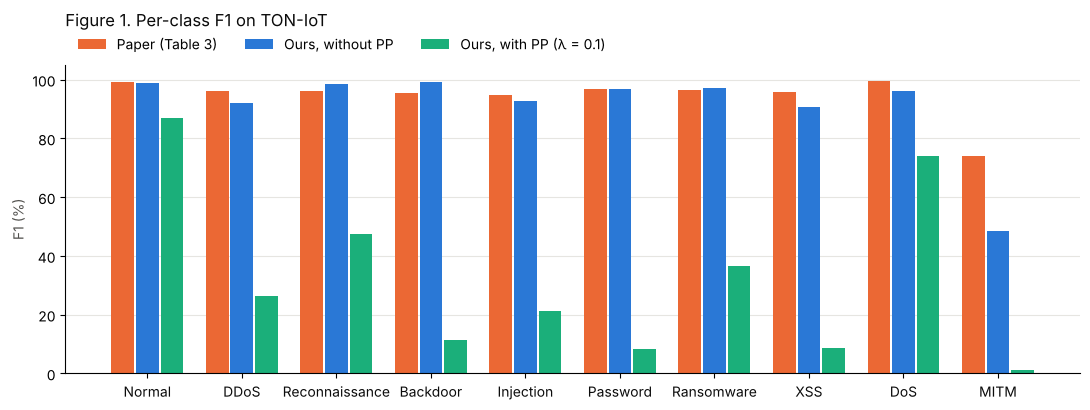

In [4]:
classes = [r["class"] for r in main["without_pp"][0]["per_class"]]
tab = {}
for k, c in enumerate(classes):
    p = PAPER_PER_CLASS["ton_iot"][c]
    tab[c] = {"paper A": p[0], "paper P": p[1], "paper R": p[2], "paper F1": p[3],
              "ours A": np.mean([r["per_class"][k]["A"] for r in main["without_pp"]]),
              "ours P": np.mean([r["per_class"][k]["P"] for r in main["without_pp"]]),
              "ours R": np.mean([r["per_class"][k]["R"] for r in main["without_pp"]]),
              "ours F1": np.mean([r["per_class"][k]["F1"] for r in main["without_pp"]]),
              "ours F1, with PP": np.mean([r["per_class"][k]["F1"] for r in main["with_pp"]]),
              "test rows": main["without_pp"][0]["per_class"][k]["support"]}
per_class = pd.DataFrame(tab).T
display(per_class.round(2))
print("'ours' = mean over 3 seeds")

# Figure 1: per-class F1 - paper vs reimplementation without PP vs with PP (three validated palette slots)
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
x = np.arange(len(classes)); w = 0.26
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, (col, color, label) in enumerate([("paper F1", ORANGE, "Paper (Table 3)"),
                                         ("ours F1", BLUE, "Ours, without PP"),
                                         ("ours F1, with PP", AQUA, "Ours, with PP (λ = 0.1)")]):
    ax.bar(x + (i - 1) * w, per_class[col].values, w - 0.02, color=color, label=label, zorder=2)
ax.set_xticks(x, classes, color=INK); ax.set_ylabel("F1 (%)", color=MUTED); ax.set_ylim(0, 105)
ax.grid(axis="y", color="#e6e5e1", zorder=0); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Figure 1. Per-class F1 on TON-IoT", loc="left", color=INK, pad=28)
plt.tight_layout(); plt.show()

### 7.3 Federated-learning performance (paper Tables 11 and 12)

| Column | Meaning |
|---|---|
| I# | The iteration at which the client converged. "10, not converged" means it never met the 0.0005 tolerance. |
| CCT | Client computation time. |
| TFD | Simulated time to receive the federated data. |
| L-A / F-A | Local / federated accuracy at the client's final iteration. |

Both are shown for seed 42, next to the paper.

**Table 11 (without PP), seed 42**

,I#,paper I#,CCT,paper CCT,TFD,paper TFD,L-A,paper L-A,F-A,paper F-A
client,,,,,,,,,,
C1,"10, not converged",9,3.6 s,7.2 s,16.4 s,27.8 s,97.57,98.24,97.78,98.34
C2,"10, not converged",9,3.9 s,7.2 s,18.8 s,30.2 s,97.50,98.15,97.50,98.34
C3,"10, not converged",9,3.8 s,7.2 s,20.8 s,37.2 s,97.61,98.03,97.81,98.34
C4,"10, not converged",10,3.8 s,10.2 s,21.8 s,35.0 s,97.26,98.23,97.61,98.21


**Table 12 (with PP), seed 42**

,I#,paper I#,CCT,paper CCT,TFD,paper TFD,L-A,paper L-A,F-A,paper F-A
client,,,,,,,,,,
C1,"10, not converged",9,3.5 s,9.3 s,16.5 s,31.8 s,97.19,98.06,77.38,98.26
C2,"10, not converged",8,3.6 s,12.5 s,18.9 s,36.8 s,96.56,98.09,77.27,98.03
C3,"10, not converged",9,3.7 s,9.6 s,20.9 s,41.2 s,96.39,98.02,74.43,98.26
C4,"10, not converged",9,3.7 s,8.6 s,21.9 s,36.2 s,96.95,98.20,74.15,98.26


**Averaged over clients and the 3 seeds**

,without_pp,with_pp
final L-A (%),97.50 ± 0.39,96.48 ± 0.61
final F-A (%),97.72 ± 0.34,73.79 ± 2.22
mean CCT (s),3.62 ± 0.16,3.56 ± 0.07
mean TFD (s),19.33 ± 0.23,19.41 ± 0.10
clients converged,0 / 12,0 / 12


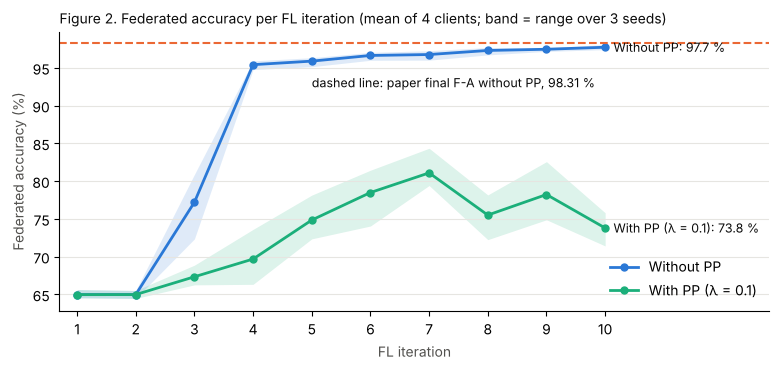

In [5]:
for m, t in (("without_pp", "Table 11 (without PP)"), ("with_pp", "Table 12 (with PP)")):
    paper = PAPER_FL["ton_iot"]["pp" if m == "with_pp" else "nopp"]
    rows = []
    for c in main[m][0]["clients"]:
        p = paper[c["client"]]
        rows.append([c["client"], f"{c['I#']}" + ("" if c["converged"] else ", not converged"), p[0],
                     f"{c['CCT_mean_s']:.1f} s", p[1], f"{c['TFD_mean_s']:.1f} s", p[2],
                     f"{c['L-A']:.2f}", p[3], f"{c['F-A']:.2f}", p[4]])
    display(Markdown(f"**{t}, seed 42**"))
    display(pd.DataFrame(rows, columns=["client", "I#", "paper I#", "CCT", "paper CCT", "TFD", "paper TFD",
                                        "L-A", "paper L-A", "F-A", "paper F-A"]).set_index("client"))
agg = pd.DataFrame({m: {"final L-A (%)": ms([np.mean([c["L-A"] for c in r["clients"]]) for r in main[m]]),
                        "final F-A (%)": ms([np.mean([c["F-A"] for c in r["clients"]]) for r in main[m]]),
                        "mean CCT (s)": ms([np.mean([c["CCT_mean_s"] for c in r["clients"]]) for r in main[m]]),
                        "mean TFD (s)": ms([np.mean([c["TFD_mean_s"] for c in r["clients"]]) for r in main[m]]),
                        "clients converged": f"{sum(c['converged'] for r in main[m] for c in r['clients'])} / 12"}
                    for m in ("without_pp", "with_pp")})
display(Markdown("**Averaged over clients and the 3 seeds**")); display(agg)

# Figure 2: federated accuracy per iteration (mean over clients, band = min-max over seeds)
fig, ax = plt.subplots(figsize=(8, 3.8))
for m, color, label in (("without_pp", BLUE, "Without PP"), ("with_pp", AQUA, "With PP (λ = 0.1)")):
    curves = []
    for r in main[m]:
        h = pd.DataFrame(r["history"]); curves.append(h.groupby("iteration")["fed_acc"].mean().values * 100)
    curves = np.array(curves); it = np.arange(1, curves.shape[1] + 1)
    ax.fill_between(it, curves.min(0), curves.max(0), color=color, alpha=0.15, linewidth=0)
    ax.plot(it, curves.mean(0), color=color, linewidth=2, marker="o", markersize=5, label=label)
    ax.annotate(f"{label}: {curves.mean(0)[-1]:.1f} %", (it[-1], curves.mean(0)[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontsize=9)
ax.axhline(98.31, color=ORANGE, linewidth=1.5, linestyle="--")
ax.annotate("dashed line: paper final F-A without PP, 98.31 %", (5, 98.31), xytext=(0, -32), textcoords="offset points",
            color=INK, fontsize=9)
ax.set_xlabel("FL iteration", color=MUTED); ax.set_ylabel("Federated accuracy (%)", color=MUTED)
ax.set_xticks(range(1, 11)); ax.grid(axis="y", color="#e6e5e1"); ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0.7, 12.8); ax.legend(frameon=False, loc="lower right")
ax.set_title("Figure 2. Federated accuracy per FL iteration (mean of 4 clients; band = range over 3 seeds)",
             loc="left", color=INK, fontsize=10)
plt.tight_layout(); plt.show()

### 7.4 Ablations of the ambiguous choices (seed 42, one change each)

,F1 without PP,F1 with PP,final F-A without PP,final F-A with PP
change,,,,
Default settings (reference),94.37,35.00,97.68,75.81
No feature scaling (literal §4.2) [A15],7.97,1.53,64.88,2.31
DP scale λ = 0.01 [A4],-,91.95,-,96.89
"DP scale λ = Δ/ε, ε = 1 [A4]",-,19.57,-,67.59
Subtract the full own noise [A2],-,31.17,-,71.11
Algorithm 1 as printed: no BatchNorm/Dropout [A1],83.27,46.83,94.14,80.37
Only the Conv1D layer is exchanged (Fig. 1) [A3],91.71,41.05,97.15,78.71


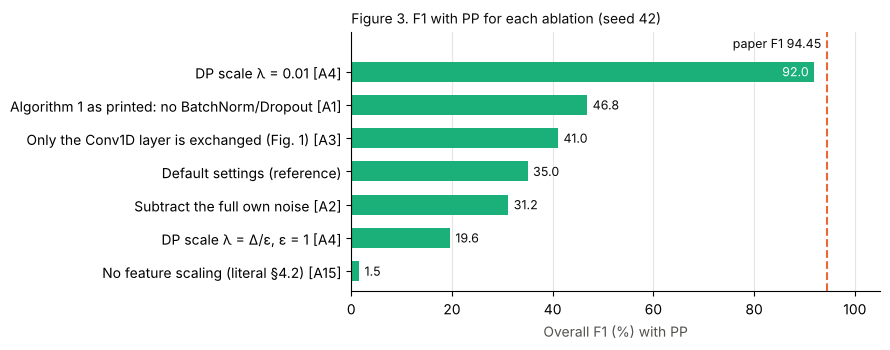

In [6]:
ablation_rows = [("Default settings (reference)", "without_pp_seed42", "with_pp_seed42"),
                 ("No feature scaling (literal §4.2) [A15]", "without_pp_abl_noscale", "with_pp_abl_noscale"),
                 ("DP scale λ = 0.01 [A4]", None, "with_pp_abl_lambda0.01"),
                 ("DP scale λ = Δ/ε, ε = 1 [A4]", None, "with_pp_abl_sensitivity"),
                 ("Subtract the full own noise [A2]", None, "with_pp_abl_ownfull"),
                 ("Algorithm 1 as printed: no BatchNorm/Dropout [A1]", "without_pp_abl_alg1", "with_pp_abl_alg1"),
                 ("Only the Conv1D layer is exchanged (Fig. 1) [A3]", "without_pp_abl_conv", "with_pp_abl_conv")]
def f1(k): return f"{R[k]['overall']['F1']:.2f}" if k else "-"
def fa(k): return f"{np.mean([c['F-A'] for c in R[k]['clients']]):.2f}" if k else "-"
display(pd.DataFrame([[n, f1(a), f1(b), fa(a), fa(b)] for n, a, b in ablation_rows],
                     columns=["change", "F1 without PP", "F1 with PP", "final F-A without PP", "final F-A with PP"]).set_index("change"))

# Figure 3: macro-F1 with PP for each DP-related choice (one series, sorted)
pp_rows = [(n, R[b]["overall"]["F1"]) for n, a, b in ablation_rows if b]
pp_rows.sort(key=lambda t: t[1])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh([n for n, _ in pp_rows], [v for _, v in pp_rows], color=AQUA, height=0.6, zorder=2)
for i, (_, v) in enumerate(pp_rows):
    inside = v > 80                                    # keep the label clear of the dashed paper line
    ax.annotate(f"{v:.1f}", (v, i), xytext=(-4 if inside else 4, 0), textcoords="offset points", va="center",
                ha="right" if inside else "left", color="white" if inside else INK, fontsize=9)
ax.axvline(PAPER_OVERALL["ton_iot"][3], color=ORANGE, linestyle="--", linewidth=1.5)
ax.set_ylim(-0.6, len(pp_rows) + 0.2)
ax.annotate(f"paper F1 {PAPER_OVERALL['ton_iot'][3]:.2f}", (PAPER_OVERALL["ton_iot"][3], len(pp_rows) - 0.15),
            xytext=(-4, 0), textcoords="offset points", ha="right", va="center", color=INK, fontsize=9)
ax.set_xlim(0, 105); ax.set_xlabel("Overall F1 (%) with PP", color=MUTED)
ax.grid(axis="x", color="#e6e5e1", zorder=0); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Figure 3. F1 with PP for each ablation (seed 42)", loc="left", color=INK, fontsize=10)
plt.tight_layout(); plt.show()

## 8. Discussion

All numbers below are from the outputs above (TON-IoT, full protocol, seeds 42, 1 and 2).

### 8.1 What reproduces
- **Detection without PP.** Seed 42 gives A 99.58 / P 96.42 / R 92.97 / F1 94.37. The paper reports
  99.63 / 96.48 / 93.18 / 94.45, so every metric is within 0.25 points.
  - Over 3 seeds the result is 99.55 ± 0.04 / 96.27 ± 0.44 / 89.70 ± 3.08 / 91.17 ± 3.14.
  - The spread comes almost entirely from **MITM**, which has only 1,043 rows (287 test rows). Its F1 is 79.3 on seed
    42 but 48.6 on average. The paper also names MITM as its weak class (F1 74.09, recall 61.0).
- **Per class (Table 3).** Most classes are within ±5 F1 of the paper.
  - Ours is higher for Reconnaissance (+2.3) and Backdoor (+3.9).
  - Ours is lower for DDoS (−3.9), DoS (−3.4) and XSS (−5.1).
- **FL accuracy without PP (Table 11).** The final local / federated accuracy is 97.50 / 97.72 %. The paper reports
  98.16 / 98.31 %.
- **The dataset is the paper's.** The 461,043 rows and the class counts match Table 1 exactly.

### 8.2 What does not reproduce
- **Accuracy with PP (Table 12).** At λ = 0.1 (the paper's worked example), the federated accuracy falls to
  73.79 ± 2.22 % and F1 to 32.22 ± 5.79. The paper reports F-A 98.20 % and an "almost unnoticeable" change.
  - The cause is the noise that stays in the federated model after each client removes its own share. It is about
    0.03 per weight, which is enough to wipe out several attack classes (Password F1 8.2, XSS 8.7, MITM 1.2).
  - With **λ = 0.01**, F1 recovers to 91.95 and F-A to 96.89 %, close to the paper. The paper's numbers are therefore
    consistent with a much smaller noise scale than its example. The paper reports neither Δ nor ε, so this cannot be
    confirmed.
- **Convergence.** No client ever met the 0.0005 tolerance (0 of 12 runs, with or without PP), so all clients ran 10
  iterations. The paper reports convergence at iteration 9.25 on average. Adam keeps moving the weights by more than
  0.0005 per iteration even at about 98 % accuracy, so the rule as specified does not trigger on this data.
- **Computation-time overhead.** The overhead of PP here is not measurable: CCT is 3.62 vs 3.56 s and TFD is
  19.33 vs 19.41 s. The paper reports +27 % CCT and +12 % TFD on TON-IoT. Absolute times also differ (hardware), so
  timing should not be compared.

### 8.3 What the ablations show
- **Feature scaling is required.** Without it (literal §4.2), the CNN predicts almost only Normal (F1 7.97 without
  PP). The paper's results imply that some scaling was used.
- **BatchNorm makes the model sensitive to the DP noise.**
  - Algorithm 1 as printed (no BatchNorm or Dropout) is weaker without PP (F1 83.27) but better with PP
    (46.83 vs 35.00).
  - Exchanging only the Conv1D layer behaves much like the default (91.71 without PP, 41.05 with PP).
- **Two alternative readings of the DP layer are worse.**
  - Subtracting the full own noise gives F1 31.17.
  - λ = Δ/ε with ε = 1 gives F1 19.57.

### 8.4 Assessment of the privacy claims
- **The "HE" layer is not homomorphic.** The server decrypts every client's model before averaging, so it protects
  nothing against the server.
- **The DP layer gives no formal guarantee.** No ε is reported, and there is no clipping (unbounded sensitivity).
  It also trades accuracy for noise in a way the paper does not report.
- **The DH layer works.** It is a pairwise-masking (secure-aggregation) scheme: the server only learns the sum, and
  the masks cancel exactly (measured residual 3.6e-11 above, float rounding).

### 8.5 Limitations of this reimplementation
- **One dataset.** Only TON-IoT was run, not the paper's other six datasets.
- **Unreported details** were filled in as assumptions; Section 2 lists them, with ablations for the important ones.
- **Not bit-reproducible with PP.** The ECDH keys come from cryptographic randomness, which cannot be seeded, and the
  resulting float64 rounding differences are amplified by training. An earlier execution of the same configuration
  gave F1 35.63 ± 6.59 with PP, against 32.22 ± 5.79 here. The conclusions are the same. Results without PP are
  bit-identical across executions.
- **Duplicates kept.** The 11,071 duplicate rows are kept, as in the paper, which may inflate test scores slightly.